
# MODULE 6: MODEL INFERENCE AND ROUTE OPTIMIZATION

## 1. Introduction

Module 6 focuses on Model Inference and Route Optimization. It uses trained machine learning models from Module 5 to analyze public transport routes, identify unusual patterns, and suggest possible improvements in route planning and scheduling.

## 2. Objectives

- Load trained machine learning models from Module 5.
- Apply existing data preprocessing techniques.
- Perform inference using K-Means, DBSCAN, Random Forest, and XGBoost.
- Identify unusual route patterns.
- Analyze route characteristics.
- Suggest route merging, splitting, and frequency adjustments.
- Simulate proposed route changes.
- Compare existing and simulated results.
- Visualize and document the findings.



## 3. Project Setup and Environment Configuration

In this section, the project directory is configured and the required Python libraries are imported for model inference and route optimization.


In [1]:

# Import required libraries

import os
import sys
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.cluster import KMeans, DBSCAN
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

print("All required libraries imported successfully!")


All required libraries imported successfully!


In [2]:

# Configure RouteRanker project directory

PROJECT_DIR = Path.cwd()

if not (PROJECT_DIR / "models").exists():
    PROJECT_DIR = PROJECT_DIR.parent

MODEL_DIR = PROJECT_DIR / "models"
DATA_DIR = PROJECT_DIR / "data" / "processed"
NOTEBOOK_DIR = PROJECT_DIR / "notebook"

print("Project Directory:", PROJECT_DIR)
print("Models Folder:", MODEL_DIR.exists())
print("Processed Data Folder:", DATA_DIR.exists())
print("Notebook Folder:", NOTEBOOK_DIR.exists())


Project Directory: C:\Users\LENOVO\OneDrive\Desktop\RouteRanker
Models Folder: True
Processed Data Folder: True
Notebook Folder: True



## 4. Loading Trained Machine Learning Models

In this section, the trained machine learning models from Module 5 are loaded for inference. These models are reused without retraining to analyze public transportation routes.


In [3]:

# Load trained machine learning models

kmeans_model = joblib.load(MODEL_DIR / "kmeans_final_model.pkl")

dbscan_model = joblib.load(MODEL_DIR / "dbscan_final_model.pkl")

random_forest_model = joblib.load(
    MODEL_DIR / "random_forest_classifier_module4.pkl"
)

xgboost_model = joblib.load(
    MODEL_DIR / "xgboost_classifier_module4.pkl"
)

print("All trained models loaded successfully!")


All trained models loaded successfully!


In [4]:

# Verify loaded machine learning models

print("K-Means Clusters:", kmeans_model.n_clusters)
print("K-Means Features:", kmeans_model.n_features_in_)

print("\nDBSCAN Epsilon:", dbscan_model.eps)
print("DBSCAN Min Samples:", dbscan_model.min_samples)

print("\nRandom Forest Features:", random_forest_model.n_features_in_)
print("Random Forest Classes:", random_forest_model.classes_)

print("\nXGBoost Features:", xgboost_model.n_features_in_)
print("XGBoost Classes:", xgboost_model.classes_)


K-Means Clusters: 4
K-Means Features: 15

DBSCAN Epsilon: 0.3
DBSCAN Min Samples: 10

Random Forest Features: 13
Random Forest Classes: [1 3]

XGBoost Features: 13
XGBoost Classes: [0 1]



## 5. Loading Preprocessing Pipeline and Dataset

In this section, the preprocessing pipeline and processed datasets from Module 4 and Module 5 are loaded. The same preprocessing transformations used during model training are maintained to ensure consistent model inference.


In [5]:

# Load the existing preprocessing pipeline

preprocessing_pipeline = joblib.load(
    DATA_DIR / "module4_preprocessing_pipeline.pkl"
)

print("Preprocessing pipeline loaded successfully!")
print("Pipeline type:", type(preprocessing_pipeline).__name__)
print("Input features:", list(preprocessing_pipeline.feature_names_in_))


Preprocessing pipeline loaded successfully!
Pipeline type: ColumnTransformer
Input features: ['scheduled_trip_count', 'stop_count', 'estimated_straight_line_route_km', 'operating_day_count', 'start_service_hour', 'end_service_hour', 'route_type', 'city', 'operates_monday', 'operates_tuesday', 'operates_wednesday', 'operates_thursday', 'operates_friday', 'operates_saturday', 'operates_sunday']


In [6]:

# Load Module 5 datasets

clustering_data = pd.read_csv(
    DATA_DIR / "module5_clustering_features.csv"
)

classification_data = pd.read_csv(
    DATA_DIR / "module5_classification_dataset_module4.csv"
)

print("Clustering Dataset Shape:", clustering_data.shape)
print("Classification Dataset Shape:", classification_data.shape)

print("\nClustering Dataset Columns:")
print(clustering_data.columns.tolist())

print("\nClassification Dataset Columns:")
print(classification_data.columns.tolist())


Clustering Dataset Shape: (7312, 15)
Classification Dataset Shape: (4721, 17)

Clustering Dataset Columns:
['numeric__scheduled_trip_count', 'numeric__stop_count', 'numeric__estimated_straight_line_route_km', 'numeric__operating_day_count', 'numeric__start_service_hour', 'numeric__end_service_hour', 'numeric__operates_monday', 'numeric__operates_tuesday', 'numeric__operates_wednesday', 'numeric__operates_thursday', 'numeric__operates_friday', 'numeric__operates_saturday', 'numeric__operates_sunday', 'categorical__route_type_1', 'categorical__route_type_3']

Classification Dataset Columns:
['route_id', 'route_short_name', 'city', 'numeric__scheduled_trip_count', 'numeric__stop_count', 'numeric__estimated_straight_line_route_km', 'numeric__operating_day_count', 'numeric__start_service_hour', 'numeric__end_service_hour', 'numeric__operates_monday', 'numeric__operates_tuesday', 'numeric__operates_wednesday', 'numeric__operates_thursday', 'numeric__operates_friday', 'numeric__operates_satur

In [7]:

print("CLUSTERING DATASET")
display(clustering_data.head())

print("\nCLASSIFICATION DATASET")
display(classification_data.head())


CLUSTERING DATASET


,numeric__scheduled_trip_count,numeric__stop_count,numeric__estimated_straight_line_route_km,numeric__operating_day_count,numeric__start_service_hour,numeric__end_service_hour,numeric__operates_monday,numeric__operates_tuesday,numeric__operates_wednesday,numeric__operates_thursday,numeric__operates_friday,numeric__operates_saturday,numeric__operates_sunday,categorical__route_type_1,categorical__route_type_3
0,0.004314,0.054156,0.062221,1.0,0.176471,0.061093,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0,1.0
1,0.010067,0.099496,0.031252,1.0,0.176471,0.067524,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0,1.0
2,0.006232,0.064232,0.020851,1.0,0.147059,0.073955,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0,1.0
3,0.002397,0.034005,0.012503,1.0,0.352941,0.070740,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0,1.0
4,0.103068,0.049118,0.089048,1.0,0.147059,0.073955,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0,1.0



CLASSIFICATION DATASET


,route_id,route_short_name,city,numeric__scheduled_trip_count,numeric__stop_count,numeric__estimated_straight_line_route_km,numeric__operating_day_count,numeric__start_service_hour,numeric__end_service_hour,numeric__operates_monday,numeric__operates_tuesday,numeric__operates_wednesday,numeric__operates_thursday,numeric__operates_friday,numeric__operates_saturday,numeric__operates_sunday,route_type
0,MTC-18751,29A,chennai,0.050336,0.035264,0.015654,1.0,0.147059,0.070740,1.0,1.0,1.0,1.0,1.0,1.0,1.0,3
1,MTC-18750,12G,chennai,0.000000,0.035264,0.045566,1.0,0.235294,0.032154,1.0,1.0,1.0,1.0,1.0,1.0,1.0,3
2,MTC-23728,11 R,chennai,0.018696,0.026448,0.016849,1.0,0.147059,0.070740,1.0,1.0,1.0,1.0,1.0,1.0,1.0,3
3,MTC-18753,22 CT,chennai,0.000000,0.030227,0.013056,1.0,0.617647,0.067524,1.0,1.0,1.0,1.0,1.0,1.0,1.0,3
4,MTC-20494,15 CT8,chennai,0.007191,0.003778,0.004138,1.0,0.117647,0.041801,1.0,1.0,1.0,1.0,1.0,1.0,1.0,3


In [8]:

# Inspect classification target labels

print("Route Type Values:")
print(classification_data["route_type"].unique())

print("\nRoute Type Distribution:")
print(classification_data["route_type"].value_counts())

print("\nRandom Forest Classes:")
print(random_forest_model.classes_)

print("\nXGBoost Classes:")
print(xgboost_model.classes_)

# Inspect saved preprocessing objects
preprocessing_objects = joblib.load(
    DATA_DIR / "preprocessing_objects.pkl"
)

print("\nSaved Preprocessing Object Names:")
print(list(preprocessing_objects.keys()))

for name, obj in preprocessing_objects.items():
    print(name, ":", type(obj).__name__)


Route Type Values:
[3 1]

Route Type Distribution:
route_type
3    3934
1     787
Name: count, dtype: int64

Random Forest Classes:
[1 3]

XGBoost Classes:
[0 1]

Saved Preprocessing Object Names:
['numeric_imputer', 'categorical_imputer', 'encoder', 'scaler', 'numeric_features', 'categorical_features']
numeric_imputer : SimpleImputer
categorical_imputer : SimpleImputer
encoder : OneHotEncoder
scaler : MinMaxScaler
numeric_features : list
categorical_features : list


In [9]:

# Inspect Module 5 notebook for XGBoost label encoding

import json

module5_path = NOTEBOOK_DIR / "module5_machine_learning.ipynb"

with open(module5_path, "r", encoding="utf-8") as file:
    module5_notebook = json.load(file)

keywords = [
    "LabelEncoder",
    "label_encoder",
    "fit_transform",
    "XGBClassifier",
    "y_encoded"
]

for cell_number, cell in enumerate(module5_notebook["cells"]):
    if cell["cell_type"] == "code":
        source = "".join(cell["source"])

        if any(word in source for word in keywords):
            print(f"\n--- Cell {cell_number + 1} ---")
            print(source)



--- Cell 10 ---
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.decomposition import PCA

PROJECT_DIR = Path(
    r"C:\Users\LENOVO\OneDrive\Desktop\RouteRanker"
)

PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
VISUAL_DIR = PROJECT_DIR / "visualizations"
VISUAL_DIR.mkdir(parents=True, exist_ok=True)

X = pd.read_csv(
    PROCESSED_DIR / "module5_clustering_features.csv"
)

cluster_data = pd.read_csv(
    PROCESSED_DIR / "kmeans_route_clusters.csv"
)

# Reduce 15 features into 2 dimensions
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

# Create visualization
plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=cluster_data["Cluster"],
    cmap="viridis",
    s=15,
    alpha=0.7
)

plt.title("K-Means Clustering Visualization (K=4)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(scatter, label="Cluster")
plt.grid(True)

plt.savefig(
    VISUAL_DIR / "kmeans


## 6. Preparing Data for Model Inference

In this section, the input features are selected from the classification dataset. The same 13 numerical features used during model training are prepared for Random Forest and XGBoost inference.

Route identifiers and route names are retained separately for identifying the predicted routes.


In [10]:

# Prepare classification features for inference

# Select the 13 numerical features
classification_features = [
    column for column in classification_data.columns
    if column.startswith("numeric__")
]

X_classification = classification_data[
    classification_features
].copy()

# Keep route information separately
route_information = classification_data[
    ["route_id", "route_short_name", "city", "route_type"]
].copy()

print("Classification feature shape:", X_classification.shape)

print("\nNumber of features:", len(classification_features))

print("\nRandom Forest expected features:",
      random_forest_model.n_features_in_)

print("XGBoost expected features:",
      xgboost_model.n_features_in_)

print("\nMissing values:", X_classification.isnull().sum().sum())

print("\nFeature preparation completed!")


Classification feature shape: (4721, 13)

Number of features: 13

Random Forest expected features: 13
XGBoost expected features: 13

Missing values: 0

Feature preparation completed!



## 7. Performing Classification Model Inference

In this section, the trained Random Forest and XGBoost models are used to predict the route types of the processed public transportation routes.

The predictions are converted into their original GTFS route type labels:
- 1 – Metro
- 3 – Bus

The original route information is combined with the predicted results for further analysis.


In [11]:

# Perform classification inference

# Random Forest predictions (original GTFS labels)
rf_predictions = random_forest_model.predict(
    X_classification
)

# XGBoost predictions (binary encoded labels)
xgb_predictions_binary = xgboost_model.predict(
    X_classification
)

# Convert XGBoost predictions to original GTFS labels
# 1 = Metro, 0 = Bus
xgb_predictions = np.where(
    xgb_predictions_binary == 1,
    1,
    3
)

# Create inference results
inference_results = route_information.copy()

inference_results["RF_Predicted_Route_Type"] = rf_predictions
inference_results["XGB_Predicted_Route_Type"] = xgb_predictions

print("Classification inference completed!")

print("\nInference Dataset Shape:",
      inference_results.shape)

print("\nFirst 10 Predictions:")
display(inference_results.head(10))


Classification inference completed!

Inference Dataset Shape: (4721, 6)

First 10 Predictions:


,route_id,route_short_name,city,route_type,RF_Predicted_Route_Type,XGB_Predicted_Route_Type
0,MTC-18751,29A,chennai,3,3,3
1,MTC-18750,12G,chennai,3,3,3
2,MTC-23728,11 R,chennai,3,3,3
3,MTC-18753,22 CT,chennai,3,3,3
4,MTC-20494,15 CT8,chennai,3,3,3
5,MTC-23729,13 R,chennai,3,3,3
6,MTC-18755,29A CT,chennai,3,3,3
7,MTC-18756,29D,chennai,3,3,3
8,MTC-18758,40A CT,chennai,3,3,3
9,MTC-4946,579K,chennai,3,3,3



## 8. Classification Prediction Analysis

In this section, the prediction distributions of Random Forest and XGBoost are analyzed. The predicted route types are compared with the actual GTFS route types to understand model performance on the processed dataset.



## 9. Classification Model Evaluation

In this section, the predicted route types are compared with the actual GTFS route types using accuracy, precision, recall, F1-score, and confusion matrices.

These evaluation metrics help us understand how well the trained models classify Bus and Metro routes.


In [12]:

# Evaluate Random Forest and XGBoost predictions

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

actual = inference_results["route_type"]

rf_pred = inference_results["RF_Predicted_Route_Type"]
xgb_pred = inference_results["XGB_Predicted_Route_Type"]

# Calculate evaluation metrics
evaluation_results = pd.DataFrame([
    {
        "Model": "Random Forest",
        "Accuracy": accuracy_score(actual, rf_pred),
        "Precision": precision_score(
            actual, rf_pred, labels=[1, 3],
            average="macro", zero_division=0
        ),
        "Recall": recall_score(
            actual, rf_pred, labels=[1, 3],
            average="macro", zero_division=0
        ),
        "F1 Score": f1_score(
            actual, rf_pred, labels=[1, 3],
            average="macro", zero_division=0
        )
    },
    {
        "Model": "XGBoost",
        "Accuracy": accuracy_score(actual, xgb_pred),
        "Precision": precision_score(
            actual, xgb_pred, labels=[1, 3],
            average="macro", zero_division=0
        ),
        "Recall": recall_score(
            actual, xgb_pred, labels=[1, 3],
            average="macro", zero_division=0
        ),
        "F1 Score": f1_score(
            actual, xgb_pred, labels=[1, 3],
            average="macro", zero_division=0
        )
    }
])

print("CLASSIFICATION MODEL EVALUATION")
display(evaluation_results.round(4))

print("\nRandom Forest Confusion Matrix:")
print(confusion_matrix(actual, rf_pred, labels=[1, 3]))

print("\nXGBoost Confusion Matrix:")
print(confusion_matrix(actual, xgb_pred, labels=[1, 3]))

print("\nEvaluation completed!")


CLASSIFICATION MODEL EVALUATION


,Model,Accuracy,Precision,Recall,F1 Score
0,Random Forest,0.9983,0.9955,0.9985,0.9970
1,XGBoost,0.9977,0.9931,0.9986,0.9958



Random Forest Confusion Matrix:
[[ 786    1]
 [   7 3927]]

XGBoost Confusion Matrix:
[[ 787    0]
 [  11 3923]]

Evaluation completed!



## 11. K-Means Model Inference

In this section, the trained K-Means model from Module 5 is used to assign each route to one of four clusters based on its operational characteristics.

The clustering results help identify groups of routes with similar scheduling, distance, stop-count, and operating-day patterns.


In [13]:

# Perform K-Means inference

# Predict clusters using the trained model
kmeans_predictions = kmeans_model.predict(clustering_data)

# Load route information
route_data = pd.read_csv(
    DATA_DIR / "module4_processed_dataset.csv"
)

# Verify row counts
if len(clustering_data) != len(route_data):
    raise ValueError("Clustering and route datasets have different row counts.")

# Create K-Means inference results
kmeans_results = route_data[
    ["route_id", "route_short_name", "city"]
].copy()

kmeans_results["KMeans_Cluster"] = kmeans_predictions

print("K-Means inference completed!")

print("\nDataset Shape:", kmeans_results.shape)

print("\nFirst 10 Cluster Assignments:")
display(kmeans_results.head(10))

print("\nCluster Distribution:")
print(
    kmeans_results["KMeans_Cluster"]
    .value_counts()
    .sort_index()
)


K-Means inference completed!

Dataset Shape: (7312, 4)

First 10 Cluster Assignments:


,route_id,route_short_name,city,KMeans_Cluster
0,101sh,101sh,ahmedabad,0
1,103-1,103,ahmedabad,0
2,103-2,103,ahmedabad,0
3,103-3,103,ahmedabad,0
4,105,105,ahmedabad,0
5,107,107,ahmedabad,0
6,109-1,109,ahmedabad,0
7,109-2,109,ahmedabad,0
8,109-3,109,ahmedabad,0
9,109-4,109,ahmedabad,0



Cluster Distribution:
KMeans_Cluster
0    6525
1     180
2     227
3     380
Name: count, dtype: int64



## 11. K-Means Model Inference

In this section, the trained K-Means model from Module 5 is used to assign each route to one of four clusters based on its operational characteristics.

The clustering results help identify groups of routes with similar scheduling, distance, stop-count, and operating-day patterns.


In [14]:

# Perform K-Means inference

# Predict clusters using the trained model
kmeans_predictions = kmeans_model.predict(clustering_data)

# Load route information
route_data = pd.read_csv(
    DATA_DIR / "module4_processed_dataset.csv"
)

# Verify row counts
if len(clustering_data) != len(route_data):
    raise ValueError("Clustering and route datasets have different row counts.")

# Create K-Means inference results
kmeans_results = route_data[
    ["route_id", "route_short_name", "city"]
].copy()

kmeans_results["KMeans_Cluster"] = kmeans_predictions

print("K-Means inference completed!")

print("\nDataset Shape:", kmeans_results.shape)

print("\nFirst 10 Cluster Assignments:")
display(kmeans_results.head(10))

print("\nCluster Distribution:")
print(
    kmeans_results["KMeans_Cluster"]
    .value_counts()
    .sort_index()
)


K-Means inference completed!

Dataset Shape: (7312, 4)

First 10 Cluster Assignments:


,route_id,route_short_name,city,KMeans_Cluster
0,101sh,101sh,ahmedabad,0
1,103-1,103,ahmedabad,0
2,103-2,103,ahmedabad,0
3,103-3,103,ahmedabad,0
4,105,105,ahmedabad,0
5,107,107,ahmedabad,0
6,109-1,109,ahmedabad,0
7,109-2,109,ahmedabad,0
8,109-3,109,ahmedabad,0
9,109-4,109,ahmedabad,0



Cluster Distribution:
KMeans_Cluster
0    6525
1     180
2     227
3     380
Name: count, dtype: int64



## 14. K-Means Cluster Characteristics Analysis

In this section, the operational characteristics of each K-Means cluster are analyzed using average scheduled trips, stop count, estimated route distance, operating days, and service hours.

This analysis helps understand the differences between route groups and identify unusual operational patterns for further investigation.


In [15]:

# Combine clustering features with predicted cluster labels

cluster_analysis = clustering_data.copy()

cluster_analysis["KMeans_Cluster"] = kmeans_predictions

# Calculate average operational characteristics
cluster_summary = cluster_analysis.groupby(
    "KMeans_Cluster"
).agg({
    "numeric__scheduled_trip_count": "mean",
    "numeric__stop_count": "mean",
    "numeric__estimated_straight_line_route_km": "mean",
    "numeric__operating_day_count": "mean",
    "numeric__start_service_hour": "mean",
    "numeric__end_service_hour": "mean"
}).round(4)

# Add number of routes in each cluster
cluster_summary.insert(
    0,
    "Total_Routes",
    cluster_analysis.groupby("KMeans_Cluster").size()
)

print("K-MEANS CLUSTER CHARACTERISTICS")
display(cluster_summary)

print("\nCluster analysis completed!")


K-MEANS CLUSTER CHARACTERISTICS


,Total_Routes,numeric__scheduled_trip_count,numeric__stop_count,numeric__estimated_straight_line_route_km,numeric__operating_day_count,numeric__start_service_hour,numeric__end_service_hour
KMeans_Cluster,,,,,,,
0,6525,0.0154,0.0456,0.0266,0.9999,0.2293,0.0708
1,180,0.0000,0.0276,0.0638,0.0000,0.3972,0.0448
2,227,0.0013,0.0263,0.0610,0.8333,0.3573,0.0429
3,380,0.0000,0.0232,0.0553,1.0000,0.3722,0.0439



Cluster analysis completed!



## 16. DBSCAN Model Inference

In this section, the DBSCAN clustering results from Module 5 are examined to identify core points, border points, and noise points.

DBSCAN identifies routes that do not belong to a sufficiently dense group of similar routes. Noise points are treated as unusual patterns that require further investigation, not automatically as inefficient routes.


In [16]:

# Analyze saved DBSCAN model results

dbscan_labels = dbscan_model.labels_

# Identify core points
core_mask = np.zeros(len(clustering_data), dtype=bool)
core_mask[dbscan_model.core_sample_indices_] = True

# Identify noise points
noise_mask = dbscan_labels == -1

# Identify border points
border_mask = (~core_mask) & (~noise_mask)

# Create DBSCAN inference results
dbscan_results = route_data[
    ["route_id", "route_short_name", "city"]
].copy()

dbscan_results["DBSCAN_Cluster"] = dbscan_labels

dbscan_results["Point_Type"] = np.select(
    [core_mask, border_mask, noise_mask],
    ["Core", "Border", "Noise"],
    default="Unknown"
)

print("DBSCAN analysis completed!")

print("\nDataset Shape:", dbscan_results.shape)

print("\nPoint Type Distribution:")
print(dbscan_results["Point_Type"].value_counts())

print("\nDBSCAN Cluster Distribution:")
print(
    dbscan_results["DBSCAN_Cluster"]
    .value_counts()
    .sort_index()
)

print("\nNoise Routes:")
display(
    dbscan_results[
        dbscan_results["Point_Type"] == "Noise"
    ].head(20)
)


DBSCAN analysis completed!

Dataset Shape: (7312, 5)

Point Type Distribution:
Point_Type
Core      7305
Noise        6
Border       1
Name: count, dtype: int64

DBSCAN Cluster Distribution:
DBSCAN_Cluster
-1       6
 0    6519
 1     227
 2     180
 3     380
Name: count, dtype: int64

Noise Routes:


,route_id,route_short_name,city,DBSCAN_Cluster,Point_Type
1449,MTC-11347,45A,chennai,-1,Noise
2508,MTC-13118,M18C,chennai,-1,Noise
2522,MTC-13124,M18C,chennai,-1,Noise
5729,219,Unknown,hyderabad,-1,Noise
6011,300,Unknown,hyderabad,-1,Noise
6192,546,Unknown,hyderabad,-1,Noise


## 17. DBSCAN Result Visualization

This section visualizes the DBSCAN clustering results using bar charts. It helps us understand the distribution of routes across clusters and identify unusual routes.

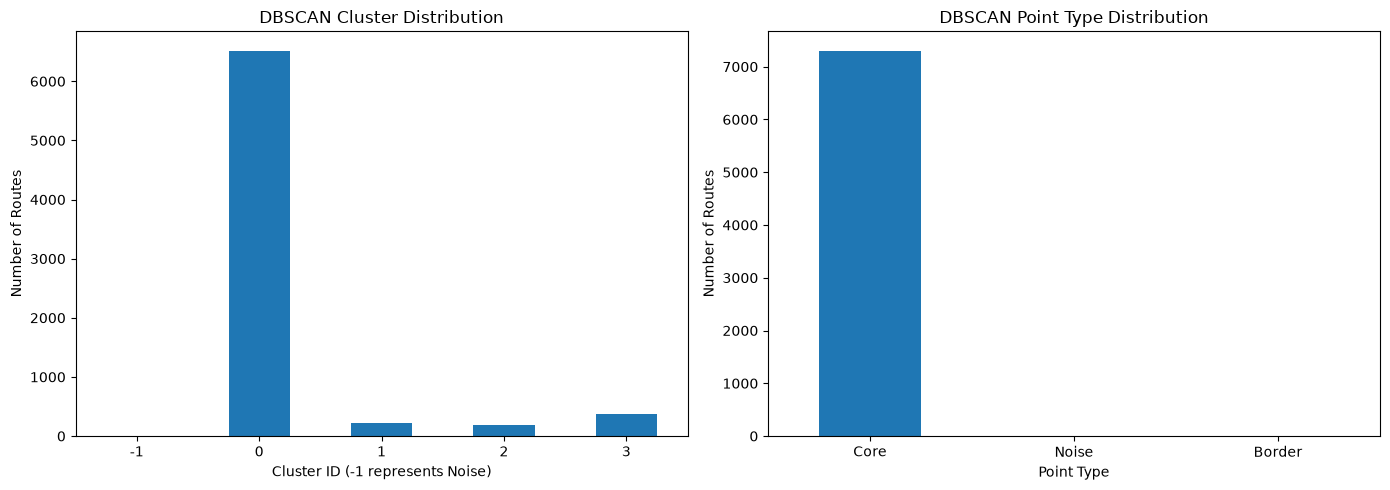

In [17]:
# Visualize DBSCAN results

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Graph 1: Cluster distribution
cluster_counts = (
    dbscan_results["DBSCAN_Cluster"]
    .value_counts()
    .sort_index()
)

cluster_counts.plot(
    kind="bar",
    ax=axes[0]
)

axes[0].set_title("DBSCAN Cluster Distribution")
axes[0].set_xlabel("Cluster ID (-1 represents Noise)")
axes[0].set_ylabel("Number of Routes")
axes[0].tick_params(axis="x", rotation=0)

# Graph 2: Point type distribution
point_counts = dbscan_results["Point_Type"].value_counts()

point_counts.plot(
    kind="bar",
    ax=axes[1]
)

axes[1].set_title("DBSCAN Point Type Distribution")
axes[1].set_xlabel("Point Type")
axes[1].set_ylabel("Number of Routes")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

## 18. Combined Clustering Analysis

In this section, K-Means and DBSCAN results are combined into a single dataset. This allows us to compare the clustering results and identify routes that need further investigation.

In [18]:
# Combine K-Means and DBSCAN results

combined_results = route_data[
    ["route_id", "route_short_name", "city"]
].copy()

combined_results["KMeans_Cluster"] = kmeans_predictions
combined_results["DBSCAN_Cluster"] = dbscan_labels
combined_results["DBSCAN_Point_Type"] = dbscan_results["Point_Type"].values

print("Combined clustering analysis completed!")

print("\nDataset Shape:")
print(combined_results.shape)

print("\nFirst 10 Records:")
display(combined_results.head(10))

print("\nK-Means and DBSCAN Comparison:")
display(
    pd.crosstab(
        combined_results["KMeans_Cluster"],
        combined_results["DBSCAN_Point_Type"]
    )
)

print("\nRoutes Identified as DBSCAN Noise:")
display(
    combined_results[
        combined_results["DBSCAN_Point_Type"] == "Noise"
    ]
)

Combined clustering analysis completed!

Dataset Shape:
(7312, 6)

First 10 Records:


,route_id,route_short_name,city,KMeans_Cluster,DBSCAN_Cluster,DBSCAN_Point_Type
0,101sh,101sh,ahmedabad,0,0,Core
1,103-1,103,ahmedabad,0,0,Core
2,103-2,103,ahmedabad,0,0,Core
3,103-3,103,ahmedabad,0,0,Core
4,105,105,ahmedabad,0,0,Core
5,107,107,ahmedabad,0,0,Core
6,109-1,109,ahmedabad,0,0,Core
7,109-2,109,ahmedabad,0,0,Core
8,109-3,109,ahmedabad,0,0,Core
9,109-4,109,ahmedabad,0,0,Core



K-Means and DBSCAN Comparison:


DBSCAN_Point_Type,Border,Core,Noise
KMeans_Cluster,,,
0,1,6518,6
1,0,180,0
2,0,227,0
3,0,380,0



Routes Identified as DBSCAN Noise:


,route_id,route_short_name,city,KMeans_Cluster,DBSCAN_Cluster,DBSCAN_Point_Type
1449,MTC-11347,45A,chennai,0,-1,Noise
2508,MTC-13118,M18C,chennai,0,-1,Noise
2522,MTC-13124,M18C,chennai,0,-1,Noise
5729,219,Unknown,hyderabad,0,-1,Noise
6011,300,Unknown,hyderabad,0,-1,Noise
6192,546,Unknown,hyderabad,0,-1,Noise


## 19. Route Characteristics Analysis

This section analyzes the original route characteristics to understand service patterns. It examines scheduled trips, number of stops, operating days, and estimated route distance.

These features help identify routes that may require further operational investigation.

In [19]:
# Check available route data columns

print("Route Dataset Shape:", route_data.shape)

print("\nAvailable Columns:")
print(route_data.columns.tolist())

print("\nFirst 5 Route Records:")
display(route_data.head())

Route Dataset Shape: (7312, 23)

Available Columns:
['route_id', 'route_short_name', 'city', 'numeric__scheduled_trip_count', 'numeric__stop_count', 'numeric__estimated_straight_line_route_km', 'numeric__operating_day_count', 'numeric__start_service_hour', 'numeric__end_service_hour', 'numeric__operates_monday', 'numeric__operates_tuesday', 'numeric__operates_wednesday', 'numeric__operates_thursday', 'numeric__operates_friday', 'numeric__operates_saturday', 'numeric__operates_sunday', 'categorical__route_type_1', 'categorical__route_type_3', 'categorical__city_ahmedabad', 'categorical__city_chennai', 'categorical__city_hyderabad', 'categorical__city_mumbai', 'categorical__city_pune']

First 5 Route Records:


,route_id,route_short_name,city,numeric__scheduled_trip_count,numeric__stop_count,numeric__estimated_straight_line_route_km,numeric__operating_day_count,numeric__start_service_hour,numeric__end_service_hour,numeric__operates_monday,...,numeric__operates_friday,numeric__operates_saturday,numeric__operates_sunday,categorical__route_type_1,categorical__route_type_3,categorical__city_ahmedabad,categorical__city_chennai,categorical__city_hyderabad,categorical__city_mumbai,categorical__city_pune
0,101sh,101sh,ahmedabad,0.004314,0.054156,0.062221,1.0,0.176471,0.061093,1.0,...,1.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0
1,103-1,103,ahmedabad,0.010067,0.099496,0.031252,1.0,0.176471,0.067524,1.0,...,1.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0
2,103-2,103,ahmedabad,0.006232,0.064232,0.020851,1.0,0.147059,0.073955,1.0,...,1.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0
3,103-3,103,ahmedabad,0.002397,0.034005,0.012503,1.0,0.352941,0.070740,1.0,...,1.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0
4,105,105,ahmedabad,0.103068,0.049118,0.089048,1.0,0.147059,0.073955,1.0,...,1.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0


## 20. Recover Original Route Features

The processed route dataset contains normalized numerical values. In this section, the saved preprocessing objects are used to understand how the original numerical features were transformed.

This helps us avoid making incorrect operational recommendations using scaled values.

In [20]:
# Load saved preprocessing objects

preprocessing_objects = joblib.load(
    DATA_DIR / "preprocessing_objects.pkl"
)

print("Available preprocessing objects:")
print(preprocessing_objects.keys())

print("\nNumeric Features:")
print(preprocessing_objects["numeric_features"])

print("\nCategorical Features:")
print(preprocessing_objects["categorical_features"])

print("\nScaler:")
print(preprocessing_objects["scaler"])

Available preprocessing objects:
dict_keys(['numeric_imputer', 'categorical_imputer', 'encoder', 'scaler', 'numeric_features', 'categorical_features'])

Numeric Features:
['scheduled_trip_count', 'stop_count', 'estimated_straight_line_route_km', 'trips_with_distance', 'operates_monday', 'operates_tuesday', 'operates_wednesday', 'operates_thursday', 'operates_friday', 'operates_saturday', 'operates_sunday', 'operating_day_count', 'start_service_hour', 'end_service_hour', 'trips_with_valid_departure']

Categorical Features:
['route_type']

Scaler:
MinMaxScaler()


In [21]:
# Inspect the saved scaler

scaler = preprocessing_objects["scaler"]

print("Number of features used by scaler:")
print(scaler.n_features_in_)

print("\nOriginal feature names:")
print(scaler.feature_names_in_)

print("\nMinimum values:")
print(scaler.data_min_)

print("\nMaximum values:")
print(scaler.data_max_)

print("\nScale values:")
print(scaler.scale_)

Number of features used by scaler:
17

Original feature names:
['scheduled_trip_count' 'stop_count' 'estimated_straight_line_route_km'
 'trips_with_distance' 'operates_monday' 'operates_tuesday'
 'operates_wednesday' 'operates_thursday' 'operates_friday'
 'operates_saturday' 'operates_sunday' 'operating_day_count'
 'start_service_hour' 'end_service_hour' 'trips_with_valid_departure'
 'route_type_1' 'route_type_3']

Minimum values:
[1. 1. 0. 1. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 1. 0. 0.]

Maximum values:
[2.08700000e+03 7.95000000e+02 7.15646185e+02 2.08700000e+03
 1.00000000e+00 1.00000000e+00 1.00000000e+00 1.00000000e+00
 1.00000000e+00 1.00000000e+00 1.00000000e+00 7.00000000e+00
 3.40000000e+01 3.11000000e+02 2.08700000e+03 1.00000000e+00
 1.00000000e+00]

Scale values:
[4.79386385e-04 1.25944584e-03 1.39733855e-03 4.79386385e-04
 1.00000000e+00 1.00000000e+00 1.00000000e+00 1.00000000e+00
 1.00000000e+00 1.00000000e+00 1.00000000e+00 1.66666667e-01
 2.94117647e-02 3.21543408e-03 4.793

In [22]:
# Recover original numerical values using the saved scaler

original_route_data = route_data[
    ["route_id", "route_short_name", "city"]
].copy()

scaler = preprocessing_objects["scaler"]

for column in route_data.columns:
    if column.startswith("numeric__"):
        feature_name = column.replace("numeric__", "")

        if feature_name in scaler.feature_names_in_:
            feature_index = list(
                scaler.feature_names_in_
            ).index(feature_name)

            original_route_data[feature_name] = (
                route_data[column] / scaler.scale_[feature_index]
                + scaler.data_min_[feature_index]
            )

# Round features that represent counts
count_columns = [
    "scheduled_trip_count",
    "stop_count",
    "operating_day_count"
]

for column in count_columns:
    if column in original_route_data.columns:
        original_route_data[column] = (
            original_route_data[column].round().astype(int)
        )

print("Original route values recovered!")

print("\nDataset Shape:")
print(original_route_data.shape)

print("\nFirst 10 Routes:")
display(original_route_data.head(10))

print("\nOriginal Feature Statistics:")
display(
    original_route_data.select_dtypes(include="number").describe().round(2)
)

Original route values recovered!

Dataset Shape:
(7312, 16)

First 10 Routes:


,route_id,route_short_name,city,scheduled_trip_count,stop_count,estimated_straight_line_route_km,operating_day_count,start_service_hour,end_service_hour,operates_monday,operates_tuesday,operates_wednesday,operates_thursday,operates_friday,operates_saturday,operates_sunday
0,101sh,101sh,ahmedabad,10,44,44.528570,7,6.0,19.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
1,103-1,103,ahmedabad,22,80,22.365598,7,6.0,21.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
2,103-2,103,ahmedabad,14,52,14.922204,7,5.0,23.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
3,103-3,103,ahmedabad,6,28,8.947943,7,12.0,22.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
4,105,105,ahmedabad,216,40,63.726733,7,5.0,23.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
5,107,107,ahmedabad,6,91,78.544870,7,6.0,21.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
6,109-1,109,ahmedabad,6,79,74.412036,7,7.0,18.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
7,109-2,109,ahmedabad,3,63,66.232570,7,12.0,20.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
8,109-3,109,ahmedabad,1,24,10.235534,7,6.0,7.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
9,109-4,109,ahmedabad,4,40,55.997036,7,7.0,17.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0



Original Feature Statistics:


,scheduled_trip_count,stop_count,estimated_straight_line_route_km,operating_day_count,start_service_hour,end_service_hour,operates_monday,operates_tuesday,operates_wednesday,operates_thursday,operates_friday,operates_saturday,operates_sunday
count,7312.00,7312.00,7312.00,7312.00,7312.00,7312.00,7312.00,7312.00,7312.00,7312.00,7312.00,7312.00,7312.00
mean,29.66,35.48,21.55,6.82,8.32,21.13,0.98,0.98,0.98,0.98,0.98,0.98,0.97
std,79.75,32.30,19.02,0.94,5.40,13.12,0.15,0.15,0.15,0.15,0.15,0.15,0.17
min,1.00,1.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,1.00,18.00,9.72,7.00,5.00,15.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
50%,5.00,28.00,17.95,7.00,6.00,20.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
75%,20.00,43.00,28.19,7.00,11.00,23.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
max,2087.00,795.00,715.65,7.00,34.00,311.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00


## 23. Detailed Analysis of Unusual Routes

This section examines the six routes identified as noise by DBSCAN. Their scheduled trips, stop counts, estimated distances, operating days, and service hours are compared to understand why they may have unusual patterns.

These routes are candidates for further investigation, not confirmed inefficient routes.

In [23]:
# Analyze DBSCAN noise routes using original values

noise_route_analysis = original_route_data.merge(
    dbscan_results[
        ["route_id", "DBSCAN_Cluster", "Point_Type"]
    ],
    on="route_id",
    how="inner"
)

noise_route_analysis = noise_route_analysis[
    noise_route_analysis["Point_Type"] == "Noise"
].copy()

columns_to_display = [
    "route_id",
    "route_short_name",
    "city",
    "scheduled_trip_count",
    "stop_count",
    "estimated_straight_line_route_km",
    "operating_day_count",
    "start_service_hour",
    "end_service_hour"
]

print("Unusual Route Analysis:")
display(
    noise_route_analysis[columns_to_display]
    .sort_values("city")
    .reset_index(drop=True)
)

print("\nComparison with Overall Route Averages:")

comparison = pd.DataFrame({
    "Overall Average": original_route_data[
        [
            "scheduled_trip_count",
            "stop_count",
            "estimated_straight_line_route_km",
            "operating_day_count"
        ]
    ].mean(),
    "Noise Route Average": noise_route_analysis[
        [
            "scheduled_trip_count",
            "stop_count",
            "estimated_straight_line_route_km",
            "operating_day_count"
        ]
    ].mean()
})

display(comparison.round(2))


Unusual Route Analysis:


,route_id,route_short_name,city,scheduled_trip_count,stop_count,estimated_straight_line_route_km,operating_day_count,start_service_hour,end_service_hour
0,MTC-11347,45A,chennai,4,11,6.122309,6,12.0,21.0
1,MTC-13118,M18C,chennai,2,13,6.398187,6,12.0,21.0
2,MTC-13124,M18C,chennai,2,10,5.178903,6,5.0,13.0
3,219,Unknown,hyderabad,2087,795,29.926609,7,3.0,71.0
4,300,Unknown,hyderabad,1314,496,30.923426,7,3.0,311.0
5,546,Unknown,hyderabad,4,42,715.646185,7,7.0,61.0
6,219,219,pune,3,118,28.714843,7,6.0,11.0



Comparison with Overall Route Averages:


,Overall Average,Noise Route Average
scheduled_trip_count,29.66,488.00
stop_count,35.48,212.14
estimated_straight_line_route_km,21.55,117.56
operating_day_count,6.82,6.57


## 23. Detailed Analysis of Unusual Routes

This section examines the six routes identified as noise by DBSCAN. Their scheduled trips, stop counts, estimated distances, operating days, and service hours are compared to understand why they may have unusual patterns.

These routes are candidates for further investigation, not confirmed inefficient routes.

In [25]:
# Correct noise-route analysis using row positions

noise_mask = (
    dbscan_results["Point_Type"].values == "Noise"
)

noise_route_analysis = original_route_data.iloc[
    np.where(noise_mask)[0]
].copy()

print("Correct Number of Noise Routes:",
      len(noise_route_analysis))

display(noise_route_analysis)

# Correct average comparison
features = [
    "scheduled_trip_count",
    "stop_count",
    "estimated_straight_line_route_km",
    "operating_day_count"
]

comparison = pd.DataFrame({
    "Overall Average": original_route_data[features].mean(),
    "Noise Route Average": noise_route_analysis[features].mean()
})

display(comparison.round(2))

Correct Number of Noise Routes: 6


,route_id,route_short_name,city,scheduled_trip_count,stop_count,estimated_straight_line_route_km,operating_day_count,start_service_hour,end_service_hour,operates_monday,operates_tuesday,operates_wednesday,operates_thursday,operates_friday,operates_saturday,operates_sunday
1449,MTC-11347,45A,chennai,4,11,6.122309,6,12.0,21.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0
2508,MTC-13118,M18C,chennai,2,13,6.398187,6,12.0,21.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0
2522,MTC-13124,M18C,chennai,2,10,5.178903,6,5.0,13.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0
5729,219,Unknown,hyderabad,2087,795,29.926609,7,3.0,71.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
6011,300,Unknown,hyderabad,1314,496,30.923426,7,3.0,311.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
6192,546,Unknown,hyderabad,4,42,715.646185,7,7.0,61.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


,Overall Average,Noise Route Average
scheduled_trip_count,29.66,568.83
stop_count,35.48,227.83
estimated_straight_line_route_km,21.55,132.37
operating_day_count,6.82,6.50


## 24. Data Quality Validation for Unusual Routes

This section checks unusual scheduled trip counts, stop counts, route distances, and service hours. It helps distinguish genuine operational patterns from possible data-quality issues before route optimization.

In [26]:
# Validate unusual route records

check_columns = [
    "scheduled_trip_count",
    "stop_count",
    "estimated_straight_line_route_km",
    "start_service_hour",
    "end_service_hour"
]

print("Unusual Route Data Validation")

# Check values exceeding normal service-time limits
print("\nRoutes with service hours >= 24:")

display(
    original_route_data[
        (original_route_data["start_service_hour"] >= 24) |
        (original_route_data["end_service_hour"] >= 24)
    ][["route_id", "route_short_name", "city"] + check_columns]
    .head(20)
)

# Show routes with the largest estimated distances
print("\nTop 10 Routes by Estimated Distance:")

display(
    original_route_data.nlargest(
        10, "estimated_straight_line_route_km"
    )[["route_id", "route_short_name", "city"] + check_columns]
)

# Show routes with the largest scheduled trip counts
print("\nTop 10 Routes by Scheduled Trips:")

display(
    original_route_data.nlargest(
        10, "scheduled_trip_count"
    )[["route_id", "route_short_name", "city"] + check_columns]
)

Unusual Route Data Validation

Routes with service hours >= 24:


,route_id,route_short_name,city,scheduled_trip_count,stop_count,estimated_straight_line_route_km,start_service_hour,end_service_hour
55,14-1,14,ahmedabad,26,71,24.458460,6.0,45.0
60,142-1,142,ahmedabad,40,58,17.268904,6.0,70.0
97,204,204,ahmedabad,8,114,75.189798,7.0,45.0
98,205,205,ahmedabad,8,114,75.189798,7.0,43.0
137,40/2-1,40/2,ahmedabad,30,100,125.566561,5.0,71.0
139,40/2-3,40/2,ahmedabad,5,40,53.655525,16.0,66.0
156,51T-1,51T,ahmedabad,72,70,27.251944,5.0,45.0
200,74-1,74,ahmedabad,24,85,24.374881,6.0,45.0
201,74-2,74,ahmedabad,8,50,14.272582,5.0,46.0
203,74/1-2,74/1,ahmedabad,9,31,7.649992,7.0,33.0



Top 10 Routes by Estimated Distance:


,route_id,route_short_name,city,scheduled_trip_count,stop_count,estimated_straight_line_route_km,start_service_hour,end_service_hour
6192,546,Unknown,hyderabad,4,42,715.646185,7.0,61.0
195,70/2,70/2,ahmedabad,24,75,170.594227,6.0,21.0
183,66/3sh-1,66/3sh,ahmedabad,2,90,157.446393,6.0,19.0
24,124,124,ahmedabad,8,75,157.424008,7.0,18.0
6969,130,130,mumbai,12,89,141.420181,6.0,27.0
5423,113M/217,Unknown,hyderabad,60,106,141.304343,4.0,140.0
158,52,52,ahmedabad,6,76,136.887104,6.0,19.0
15,117/1-1,117/1,ahmedabad,24,54,134.941248,5.0,23.0
6146,498VS,Unknown,hyderabad,6,77,132.727469,4.0,75.0
5521,171/219,Unknown,hyderabad,1,38,127.021166,7.0,21.0



Top 10 Routes by Scheduled Trips:


,route_id,route_short_name,city,scheduled_trip_count,stop_count,estimated_straight_line_route_km,start_service_hour,end_service_hour
5729,219,Unknown,hyderabad,2087,795,29.926609,3.0,71.0
6011,300,Unknown,hyderabad,1314,496,30.923426,3.0,311.0
5397,10H,Unknown,hyderabad,1161,270,18.395407,4.0,64.0
6523,117RING,117RING,mumbai,930,15,1.484540,0.0,24.0
6522,116AS,116AS,mumbai,911,11,1.876968,6.0,22.0
6561,182RING,182RING,mumbai,904,21,3.045254,7.0,21.0
6772,401AS,401AS,mumbai,830,9,1.873953,0.0,22.0
6678,310-1,310,mumbai,827,41,6.641316,0.0,24.0
6642,273AS-2,273AS,mumbai,812,37,5.654057,0.0,24.0
6595,217-1,217,mumbai,789,22,3.411708,0.0,24.0


## 25. Statistical Outlier Detection

The Interquartile Range (IQR) method is used to identify unusually high route characteristics. The results are compared with DBSCAN noise routes to identify records that need further investigation.

Outliers are not automatically classified as inefficient routes.

In [27]:
# Statistical outlier detection using IQR

features_to_check = [
    "scheduled_trip_count",
    "stop_count",
    "estimated_straight_line_route_km"
]

outlier_limits = {}

for feature in features_to_check:
    Q1 = original_route_data[feature].quantile(0.25)
    Q3 = original_route_data[feature].quantile(0.75)
    IQR = Q3 - Q1

    upper_limit = Q3 + (1.5 * IQR)

    outlier_limits[feature] = upper_limit

    print(f"{feature}")
    print(f"Upper IQR Limit: {upper_limit:.2f}\n")

# Examine the six DBSCAN noise routes
outlier_check = noise_route_analysis.copy()

for feature in features_to_check:
    outlier_check[f"{feature}_Outlier"] = (
        outlier_check[feature] > outlier_limits[feature]
    )

# Flag extended service hours for manual review
outlier_check["Extended_Service_Hours"] = (
    outlier_check["end_service_hour"] >= 48
)

print("Noise Route Outlier Assessment:")

display(
    outlier_check[
        [
            "route_id",
            "city",
            "scheduled_trip_count",
            "scheduled_trip_count_Outlier",
            "stop_count",
            "stop_count_Outlier",
            "estimated_straight_line_route_km",
            "estimated_straight_line_route_km_Outlier",
            "end_service_hour",
            "Extended_Service_Hours"
        ]
    ].reset_index(drop=True)
)

scheduled_trip_count
Upper IQR Limit: 48.50

stop_count
Upper IQR Limit: 80.50

estimated_straight_line_route_km
Upper IQR Limit: 55.88

Noise Route Outlier Assessment:


,route_id,city,scheduled_trip_count,scheduled_trip_count_Outlier,stop_count,stop_count_Outlier,estimated_straight_line_route_km,estimated_straight_line_route_km_Outlier,end_service_hour,Extended_Service_Hours
0,MTC-11347,chennai,4,False,11,False,6.122309,False,21.0,False
1,MTC-13118,chennai,2,False,13,False,6.398187,False,21.0,False
2,MTC-13124,chennai,2,False,10,False,5.178903,False,13.0,False
3,219,hyderabad,2087,True,795,True,29.926609,False,71.0,True
4,300,hyderabad,1314,True,496,True,30.923426,False,311.0,True
5,546,hyderabad,4,False,42,False,715.646185,True,61.0,True


## 26. Route Investigation and Improvement Recommendations

Based on DBSCAN and IQR analysis, routes requiring further investigation are categorized according to their unusual characteristics.

The recommendations are preliminary and do not automatically modify existing routes.

In [28]:
# Generate route investigation recommendations

def recommend_investigation(row):

    reasons = []

    if row["scheduled_trip_count_Outlier"]:
        reasons.append("Unusually high scheduled trip count")

    if row["stop_count_Outlier"]:
        reasons.append("Unusually high stop count")

    if row["estimated_straight_line_route_km_Outlier"]:
        reasons.append("Unusually high estimated route distance")

    if row["Extended_Service_Hours"]:
        reasons.append("Extended GTFS service hours")

    if not reasons:
        return pd.Series({
            "Investigation_Status": "Review Required",
            "Investigation_Reason": "DBSCAN noise; review schedule and route coverage",
            "Suggested_Action": "Verify service schedule and route connectivity"
        })

    if row["estimated_straight_line_route_km_Outlier"]:
        action = "Verify stop coordinates and route distance calculation"

    elif row["scheduled_trip_count_Outlier"] or row["stop_count_Outlier"]:
        action = "Validate trip records, stop sequences and service times"

    else:
        action = "Review extended GTFS service-time records"

    return pd.Series({
        "Investigation_Status": "Priority Investigation",
        "Investigation_Reason": "; ".join(reasons),
        "Suggested_Action": action
    })


recommendation_columns = outlier_check.apply(
    recommend_investigation,
    axis=1
)

route_recommendations = pd.concat(
    [
        outlier_check[
            ["route_id", "city"]
        ].reset_index(drop=True),
        recommendation_columns.reset_index(drop=True)
    ],
    axis=1
)

print("Route Investigation Recommendations:")
display(route_recommendations)

Route Investigation Recommendations:


,route_id,city,Investigation_Status,Investigation_Reason,Suggested_Action
0,MTC-11347,chennai,Review Required,DBSCAN noise; review schedule and route coverage,Verify service schedule and route connectivity
1,MTC-13118,chennai,Review Required,DBSCAN noise; review schedule and route coverage,Verify service schedule and route connectivity
2,MTC-13124,chennai,Review Required,DBSCAN noise; review schedule and route coverage,Verify service schedule and route connectivity
3,219,hyderabad,Priority Investigation,Unusually high scheduled trip count; Unusually...,"Validate trip records, stop sequences and serv..."
4,300,hyderabad,Priority Investigation,Unusually high scheduled trip count; Unusually...,"Validate trip records, stop sequences and serv..."
5,546,hyderabad,Priority Investigation,Unusually high estimated route distance; Exten...,Verify stop coordinates and route distance cal...



## 27.Checking Original GTFS Data for Route Optimization

This step checks the availability of original GTFS files required to validate route schedules, stop sequences, and route information before performing optimization.

In [29]:
# Check available project folders and GTFS data

print("Project Directory:", PROJECT_DIR)

print("\nAvailable Main Folders:")
for item in PROJECT_DIR.iterdir():
    if item.is_dir():
        print(item.name)

print("\nSearching for important GTFS files:")

gtfs_files = []

for file_name in ["routes.txt", "trips.txt", "stop_times.txt", "stops.txt"]:
    matches = list(PROJECT_DIR.rglob(file_name))
    print(f"\n{file_name}: {len(matches)} file(s) found")

    for path in matches[:10]:
        print(path.relative_to(PROJECT_DIR))
        gtfs_files.append(path)

print("\nTotal GTFS files found:", len(gtfs_files))

Project Directory: C:\Users\LENOVO\OneDrive\Desktop\RouteRanker

Available Main Folders:
.git
.ipynb_checkpoints
data
models
module6
notebook
reports
src
visualizations

Searching for important GTFS files:

routes.txt: 5 file(s) found
data\raw\ahmedabad\routes.txt
data\raw\chennai\routes.txt
data\raw\hyderabad\routes.txt
data\raw\mumbai\routes.txt
data\raw\pune\routes.txt

trips.txt: 5 file(s) found
data\raw\ahmedabad\trips.txt
data\raw\chennai\trips.txt
data\raw\hyderabad\trips.txt
data\raw\mumbai\trips.txt
data\raw\pune\trips.txt

stop_times.txt: 5 file(s) found
data\raw\ahmedabad\stop_times.txt
data\raw\chennai\stop_times.txt
data\raw\hyderabad\stop_times.txt
data\raw\mumbai\stop_times.txt
data\raw\pune\stop_times.txt

stops.txt: 5 file(s) found
data\raw\ahmedabad\stops.txt
data\raw\chennai\stops.txt
data\raw\hyderabad\stops.txt
data\raw\mumbai\stops.txt
data\raw\pune\stops.txt

Total GTFS files found: 20


## 28. Original GTFS Route Validation

This step validates the six routes identified during DBSCAN and IQR analysis using original GTFS data. It checks route details, scheduled trips, stop sequences, service times, and stop coordinates.

In [31]:

# Load original GTFS files for the six investigation routes

gtfs_base = PROJECT_DIR / "data" / "raw"

investigation_routes = {
    "chennai": ["MTC-11347", "MTC-13118", "MTC-13124"],
    "hyderabad": ["219", "300", "546"]
}

gtfs_data = {}

for city, route_ids in investigation_routes.items():

    city_folder = gtfs_base / city

    routes = pd.read_csv(city_folder / "routes.txt", dtype=str)
    trips = pd.read_csv(city_folder / "trips.txt", dtype=str)
    stop_times = pd.read_csv(city_folder / "stop_times.txt", dtype=str)
    stops = pd.read_csv(city_folder / "stops.txt", dtype=str)

    gtfs_data[city] = {
        "routes": routes,
        "trips": trips,
        "stop_times": stop_times,
        "stops": stops
    }

    print(f"\n{city.upper()}")
    print("Routes:", routes.shape)
    print("Trips:", trips.shape)
    print("Stop times:", stop_times.shape)
    print("Stops:", stops.shape)

    print("\nRoute ID column:", routes.columns.tolist())
    print("Trip ID column:", trips.columns.tolist())
    print("Stop sequence columns:", stop_times.columns.tolist())



CHENNAI
Routes: (5402, 8)
Trips: (48435, 6)
Stop times: (1389081, 5)
Stops: (6542, 10)

Route ID column: ['route_id', 'route_short_name', 'route_long_name', 'route_type', 'agency_id', 'route_desc', 'route_color', 'route_text_color']
Trip ID column: ['trip_id', 'route_id', 'service_id', 'direction_id', 'trip_headsign', 'shape_id']
Stop sequence columns: ['trip_id', 'arrival_time', 'departure_time', 'stop_id', 'stop_sequence']

HYDERABAD
Routes: (1031, 4)
Trips: (44892, 5)
Stop times: (1132807, 6)
Stops: (5028, 6)

Route ID column: ['route_id', 'route_long_name', 'agency_id', 'route_type']
Trip ID column: ['route_id', 'trip_id', 'service_id', 'direction_id', 'trip_short_name']
Stop sequence columns: ['trip_id', 'stop_sequence', 'stop_id', 'departure_time', 'arrival_time', 'timepoint']


In [32]:

# Validate investigation routes against original GTFS data

route_validation = []

for city, route_ids in investigation_routes.items():

    city_data = gtfs_data[city]

    routes = city_data["routes"]
    trips = city_data["trips"]

    for route_id in route_ids:

        matching_routes = routes[
            routes["route_id"] == route_id
        ]

        matching_trips = trips[
            trips["route_id"] == route_id
        ]

        route_validation.append({
            "city": city,
            "route_id": route_id,
            "Route_Found": len(matching_routes) > 0,
            "Original_Trip_Count": len(matching_trips),
            "Route_Name": (
                matching_routes.iloc[0].get(
                    "route_long_name", "Not Available"
                )
                if len(matching_routes) > 0
                else "Not Found"
            )
        })

route_validation_df = pd.DataFrame(route_validation)

print("Original GTFS Route Validation:")
display(route_validation_df)


Original GTFS Route Validation:


,city,route_id,Route_Found,Original_Trip_Count,Route_Name
0,chennai,MTC-11347,True,4,Madipakkam B.T TO N.G.O.Colony
1,chennai,MTC-13118,True,2,Keelkattalai TO N.G.O.Colony
2,chennai,MTC-13124,True,2,N.G.O.Colony TO Thyagaraya Nagar
3,hyderabad,219,True,2087,219
4,hyderabad,300,True,1314,300
5,hyderabad,546,True,4,546


## 29. Stop Sequence and Service Time Analysis

This step examines the original stop-time records for the six investigation routes. It checks the number of stops, missing stop references, stop sequence consistency, service duration, and available stop coordinates.

In [34]:

# Analyze original stop sequences and service times

def gtfs_time_to_seconds(value):
    try:
        if pd.isna(value):
            return np.nan

        parts = str(value).split(":")
        if len(parts) != 3:
            return np.nan

        hours, minutes, seconds = map(int, parts)
        return hours * 3600 + minutes * 60 + seconds

    except (ValueError, TypeError):
        return np.nan


stop_analysis = []
trip_analysis = []

for city, route_ids in investigation_routes.items():

    city_data = gtfs_data[city]

    trips = city_data["trips"]
    stop_times = city_data["stop_times"]
    stops = city_data["stops"]

    for route_id in route_ids:

        route_trips = trips[
            trips["route_id"] == route_id
        ].copy()

        trip_ids = route_trips["trip_id"].dropna().unique()

        route_stop_times = stop_times[
            stop_times["trip_id"].isin(trip_ids)
        ].copy()

        route_stop_times["arrival_seconds"] = (
            route_stop_times["arrival_time"]
            .apply(gtfs_time_to_seconds)
        )

        route_stop_times["departure_seconds"] = (
            route_stop_times["departure_time"]
            .apply(gtfs_time_to_seconds)
        )

        route_stop_times["stop_sequence_numeric"] = pd.to_numeric(
            route_stop_times["stop_sequence"],
            errors="coerce"
        )

        # Check stop references
        valid_stop_ids = set(stops["stop_id"].dropna())
        missing_stop_refs = (
            ~route_stop_times["stop_id"].isin(valid_stop_ids)
        ).sum()

        # Analyze individual trips
        for trip_id, group in route_stop_times.groupby("trip_id"):

            sequence = group["stop_sequence_numeric"]

            duplicate_sequences = sequence.duplicated().sum()

            sequence_order = (
                sequence.dropna().is_monotonic_increasing
            )

            arrival = group["arrival_seconds"].dropna()
            departure = group["departure_seconds"].dropna()

            trip_analysis.append({
                "city": city,
                "route_id": route_id,
                "trip_id": trip_id,
                "Stop_Count": len(group),
                "Duplicate_Sequences": duplicate_sequences,
                "Sequence_Increasing": sequence_order,
                "First_Arrival_Hour": (
                    arrival.min() / 3600 if len(arrival) else np.nan
                ),
                "Last_Departure_Hour": (
                    departure.max() / 3600 if len(departure) else np.nan
                )
            })

        # Check coordinates where available
        coordinate_columns = [
            column for column in ["stop_lat", "stop_lon"]
            if column in stops.columns
        ]

        coordinate_data = stops[
            stops["stop_id"].isin(
                route_stop_times["stop_id"].dropna().unique()
            )
        ]

        stop_analysis.append({
            "city": city,
            "route_id": route_id,
            "Trip_Count": len(route_trips),
            "Stop_Time_Rows": len(route_stop_times),
            "Unique_Stops": route_stop_times["stop_id"].nunique(),
            "Missing_Stop_References": int(missing_stop_refs),
            "Missing_Arrival_Times": int(
                route_stop_times["arrival_seconds"].isna().sum()
            ),
            "Missing_Departure_Times": int(
                route_stop_times["departure_seconds"].isna().sum()
            ),
            "Available_Coordinate_Columns": ", ".join(
                coordinate_columns
            ) if coordinate_columns else "Not Available"
        })

stop_analysis_df = pd.DataFrame(stop_analysis)
trip_analysis_df = pd.DataFrame(trip_analysis)

print("ROUTE-LEVEL STOP ANALYSIS")
display(stop_analysis_df)

print("\nTRIP-LEVEL STOP AND SERVICE TIME ANALYSIS")
display(trip_analysis_df)


ROUTE-LEVEL STOP ANALYSIS


,city,route_id,Trip_Count,Stop_Time_Rows,Unique_Stops,Missing_Stop_References,Missing_Arrival_Times,Missing_Departure_Times,Available_Coordinate_Columns
0,chennai,MTC-11347,4,44,11,0,0,0,"stop_lat, stop_lon"
1,chennai,MTC-13118,2,26,13,0,0,0,"stop_lat, stop_lon"
2,chennai,MTC-13124,2,20,10,0,0,0,"stop_lat, stop_lon"
3,hyderabad,219,2087,65868,795,0,0,0,"stop_lat, stop_lon"
4,hyderabad,300,1314,46235,496,0,0,0,"stop_lat, stop_lon"
5,hyderabad,546,4,100,42,0,0,0,"stop_lat, stop_lon"



TRIP-LEVEL STOP AND SERVICE TIME ANALYSIS


,city,route_id,trip_id,Stop_Count,Duplicate_Sequences,Sequence_Increasing,First_Arrival_Hour,Last_Departure_Hour
0,chennai,MTC-11347,MTC-89829,11,0,True,12.416667,12.800000
1,chennai,MTC-11347,MTC-89836,11,0,True,20.666667,21.050000
2,chennai,MTC-11347,MTC-89845,11,0,True,12.750000,13.133333
3,chennai,MTC-11347,MTC-89852,11,0,True,21.000000,21.383333
4,chennai,MTC-13118,MTC-89895,13,0,True,12.583333,12.916667
...,...,...,...,...,...,...,...,...
3408,hyderabad,300,998534,36,0,True,18.883333,44.341667
3409,hyderabad,546,41846430,24,0,True,7.916667,29.886667
3410,hyderabad,546,41846431,23,0,True,10.000000,33.489722
3411,hyderabad,546,41846434,24,0,True,15.666667,37.636667


## 30. Trip Duration and Time Consistency Analysis

This step examines trip duration, extended GTFS service times, and chronological consistency between stops. It helps identify records that require further validation before route optimization.

In [36]:

# Analyze trip duration and chronological consistency

trip_quality = []

for city, route_ids in investigation_routes.items():

    city_data = gtfs_data[city]
    trips = city_data["trips"]
    stop_times = city_data["stop_times"]

    for route_id in route_ids:

        route_trips = trips[trips["route_id"] == route_id]
        trip_ids = route_trips["trip_id"].dropna().unique()

        route_stop_times = stop_times[
            stop_times["trip_id"].isin(trip_ids)
        ].copy()

        route_stop_times["sequence"] = pd.to_numeric(
            route_stop_times["stop_sequence"],
            errors="coerce"
        )

        route_stop_times["arrival_sec"] = (
            route_stop_times["arrival_time"]
            .apply(gtfs_time_to_seconds)
        )

        route_stop_times["departure_sec"] = (
            route_stop_times["departure_time"]
            .apply(gtfs_time_to_seconds)
        )

        for trip_id, group in route_stop_times.groupby("trip_id"):

            group = group.sort_values("sequence")

            times = []

            for _, row in group.iterrows():
                for col in ["arrival_sec", "departure_sec"]:
                    if pd.notna(row[col]):
                        times.append(row[col])

            time_differences = np.diff(times) if len(times) > 1 else []

            first_time = times[0] if times else np.nan
            last_time = times[-1] if times else np.nan

            duration_hours = (
                (last_time - first_time) / 3600
                if len(times) > 1 else np.nan
            )

            trip_quality.append({
                "city": city,
                "route_id": route_id,
                "trip_id": trip_id,
                "Duration_Hours": duration_hours,
                "Maximum_GTFS_Hour": (
                    last_time / 3600 if len(times) else np.nan
                ),
                "Negative_Time_Jumps": int(
                    np.sum(np.array(time_differences) < 0)
                ),
                "Service_Over_24_Hours": (
                    last_time >= 24 * 3600
                    if len(times) else False
                ),
                "Service_Over_48_Hours": (
                    last_time >= 48 * 3600
                    if len(times) else False
                )
            })

trip_quality_df = pd.DataFrame(trip_quality)

print("Trip Quality Summary:")

trip_quality_summary = trip_quality_df.groupby(
    ["city", "route_id"]
).agg(
    Trip_Count=("trip_id", "count"),
    Average_Duration_Hours=("Duration_Hours", "mean"),
    Maximum_Duration_Hours=("Duration_Hours", "max"),
    Maximum_GTFS_Hour=("Maximum_GTFS_Hour", "max"),
    Trips_With_Negative_Time_Jumps=("Negative_Time_Jumps",
                                    lambda x: (x > 0).sum()),
    Trips_Over_24_Hours=("Service_Over_24_Hours", "sum"),
    Trips_Over_48_Hours=("Service_Over_48_Hours", "sum")
).reset_index()

display(trip_quality_summary)

print("\nTrips with service extending beyond 48 GTFS hours:")
display(
    trip_quality_df[
        trip_quality_df["Service_Over_48_Hours"]
    ].sort_values("Maximum_GTFS_Hour", ascending=False).head(15)
)


Trip Quality Summary:


,city,route_id,Trip_Count,Average_Duration_Hours,Maximum_Duration_Hours,Maximum_GTFS_Hour,Trips_With_Negative_Time_Jumps,Trips_Over_24_Hours,Trips_Over_48_Hours
0,chennai,MTC-11347,4,0.383333,0.383333,21.383333,0,0,0
1,chennai,MTC-13118,2,0.333333,0.333333,21.166667,0,0,0
2,chennai,MTC-13124,2,0.250000,0.250000,13.500000,0,0,0
3,hyderabad,219,2087,21.646891,61.319722,71.571667,0,1680,247
4,hyderabad,300,1314,24.704292,303.882778,311.966111,0,1263,151
5,hyderabad,546,4,27.879167,44.086944,61.920278,0,4,1



Trips with service extending beyond 48 GTFS hours:


,city,route_id,trip_id,Duration_Hours,Maximum_GTFS_Hour,Negative_Time_Jumps,Service_Over_24_Hours,Service_Over_48_Hours
2423,hyderabad,300,41738902,303.882778,311.966111,0,True,True
2422,hyderabad,300,41738901,236.810556,243.227222,0,True,True
1310,hyderabad,219,41806042,60.321667,71.571667,0,True,True
886,hyderabad,219,41756220,56.236111,71.569444,0,True,True
2044,hyderabad,219,41855872,37.934444,70.851111,0,True,True
1360,hyderabad,219,41809474,61.319722,70.069722,0,True,True
91,hyderabad,219,1373384,61.319722,69.403056,0,True,True
101,hyderabad,219,1374649,61.319722,69.319722,0,True,True
2678,hyderabad,300,41749590,34.363889,68.597222,0,True,True
2367,hyderabad,300,41733430,34.363889,68.530556,0,True,True


## 31. Original GTFS Route Distance Validation

This step estimates route distances using the Haversine formula and original GTFS stop coordinates. It compares distances across trips to identify unusual route-distance records.

Note: These are straight-line distances between consecutive stops, not actual road distances.

In [37]:

# Calculate approximate route distances using original stop coordinates

def haversine_km(lat1, lon1, lat2, lon2):
    earth_radius = 6371.0

    lat1, lon1, lat2, lon2 = np.radians(
        [lat1, lon1, lat2, lon2]
    )

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2)
        * np.sin(dlon / 2) ** 2
    )

    return 2 * earth_radius * np.arcsin(np.sqrt(a))


distance_results = []

for city, route_ids in investigation_routes.items():

    city_data = gtfs_data[city]

    trips = city_data["trips"]
    stop_times = city_data["stop_times"]
    stops = city_data["stops"].copy()

    stops["stop_lat"] = pd.to_numeric(
        stops["stop_lat"], errors="coerce"
    )
    stops["stop_lon"] = pd.to_numeric(
        stops["stop_lon"], errors="coerce"
    )

    stops = stops.dropna(subset=["stop_lat", "stop_lon"])

    for route_id in route_ids:

        route_trips = trips[
            trips["route_id"] == route_id
        ]

        trip_ids = route_trips["trip_id"].dropna().unique()

        route_stop_times = stop_times[
            stop_times["trip_id"].isin(trip_ids)
        ].copy()

        route_stop_times["stop_sequence"] = pd.to_numeric(
            route_stop_times["stop_sequence"],
            errors="coerce"
        )

        route_stop_times = route_stop_times.merge(
            stops[["stop_id", "stop_lat", "stop_lon"]],
            on="stop_id",
            how="left"
        )

        trip_distances = []
        trips_without_coordinates = 0

        for trip_id, group in route_stop_times.groupby("trip_id"):

            group = group.sort_values("stop_sequence")

            coordinates = group.dropna(
                subset=["stop_lat", "stop_lon"]
            )

            if len(coordinates) < 2:
                trips_without_coordinates += 1
                continue

            latitudes = coordinates["stop_lat"].to_numpy()
            longitudes = coordinates["stop_lon"].to_numpy()

            segment_distances = haversine_km(
                latitudes[:-1],
                longitudes[:-1],
                latitudes[1:],
                longitudes[1:]
            )

            trip_distances.append(segment_distances.sum())

        distance_results.append({
            "city": city,
            "route_id": route_id,
            "Trips_Analyzed": len(trip_distances),
            "Trips_Without_Sufficient_Coordinates": trips_without_coordinates,
            "Average_Straight_Line_Km": (
                np.mean(trip_distances) if trip_distances else np.nan
            ),
            "Median_Straight_Line_Km": (
                np.median(trip_distances) if trip_distances else np.nan
            ),
            "Maximum_Straight_Line_Km": (
                np.max(trip_distances) if trip_distances else np.nan
            ),
            "Minimum_Straight_Line_Km": (
                np.min(trip_distances) if trip_distances else np.nan
            )
        })

distance_validation_df = pd.DataFrame(distance_results)

print("Original GTFS Coordinate-Based Distance Validation:")
display(distance_validation_df)


Original GTFS Coordinate-Based Distance Validation:


,city,route_id,Trips_Analyzed,Trips_Without_Sufficient_Coordinates,Average_Straight_Line_Km,Median_Straight_Line_Km,Maximum_Straight_Line_Km,Minimum_Straight_Line_Km
0,chennai,MTC-11347,4,0,6.122300,6.122300,6.122300,6.122300
1,chennai,MTC-13118,2,0,6.398179,6.398179,6.398179,6.398179
2,chennai,MTC-13124,2,0,5.178895,5.178895,5.178895,5.178895
3,hyderabad,219,2087,0,28.922234,29.926568,264.808908,1.345401
4,hyderabad,300,1314,0,31.613073,30.923384,438.520475,1.723144
5,hyderabad,546,4,0,718.298025,715.645197,1390.698563,51.203144


## 32. Detailed Stop-to-Stop Distance Investigation

This step identifies unusually large distances between consecutive stops in Hyderabad route 546. It examines stop IDs, coordinates, sequence numbers, and trip-level distance totals.

In [38]:

# Investigate unusually large stop-to-stop distances in Hyderabad route 546

city = "hyderabad"
route_id = "546"

trips = gtfs_data[city]["trips"]
stop_times = gtfs_data[city]["stop_times"]
stops = gtfs_data[city]["stops"].copy()

route_trip_ids = trips.loc[
    trips["route_id"] == route_id, "trip_id"
].dropna().unique()

route_stops = stop_times[
    stop_times["trip_id"].isin(route_trip_ids)
].copy()

route_stops["stop_sequence"] = pd.to_numeric(
    route_stops["stop_sequence"], errors="coerce"
)

stops["stop_lat"] = pd.to_numeric(
    stops["stop_lat"], errors="coerce"
)
stops["stop_lon"] = pd.to_numeric(
    stops["stop_lon"], errors="coerce"
)

stop_name_column = (
    "stop_name" if "stop_name" in stops.columns else None
)

selected_stop_columns = ["stop_id", "stop_lat", "stop_lon"]

if stop_name_column:
    selected_stop_columns.append(stop_name_column)

route_stops = route_stops.merge(
    stops[selected_stop_columns],
    on="stop_id",
    how="left"
)

segment_results = []

for trip_id, group in route_stops.groupby("trip_id"):

    group = group.sort_values("stop_sequence").reset_index(drop=True)

    for i in range(len(group) - 1):

        current = group.iloc[i]
        following = group.iloc[i + 1]

        if pd.isna(current["stop_lat"]) or pd.isna(following["stop_lat"]):
            continue

        distance = haversine_km(
            current["stop_lat"],
            current["stop_lon"],
            following["stop_lat"],
            following["stop_lon"]
        )

        segment_results.append({
            "trip_id": trip_id,
            "From_Stop": current["stop_id"],
            "To_Stop": following["stop_id"],
            "From_Sequence": current["stop_sequence"],
            "To_Sequence": following["stop_sequence"],
            "From_Lat": current["stop_lat"],
            "From_Lon": current["stop_lon"],
            "To_Lat": following["stop_lat"],
            "To_Lon": following["stop_lon"],
            "Segment_Distance_Km": distance
        })

segment_analysis_df = pd.DataFrame(segment_results)

print("Trip-wise Distance Summary:")

trip_distance_summary = segment_analysis_df.groupby(
    "trip_id"
).agg(
    Stop_Segments=("Segment_Distance_Km", "count"),
    Total_Distance_Km=("Segment_Distance_Km", "sum"),
    Maximum_Segment_Km=("Segment_Distance_Km", "max")
).reset_index()

display(trip_distance_summary)

print("\n10 Largest Stop-to-Stop Distances:")

display(
    segment_analysis_df.sort_values(
        "Segment_Distance_Km",
        ascending=False
    ).head(10)
)


Trip-wise Distance Summary:


,trip_id,Stop_Segments,Total_Distance_Km,Maximum_Segment_Km
0,41846430,23,51.203144,4.719419
1,41846431,22,1380.087249,198.968409
2,41846434,23,51.203144,4.719419
3,41846435,28,1390.698563,198.968409



10 Largest Stop-to-Stop Distances:


,trip_id,From_Stop,To_Stop,From_Sequence,To_Sequence,From_Lat,From_Lon,To_Lat,To_Lon,Segment_Distance_Km
30,41846431,DB3FwFXW,BvCdGGJa,8,9,16.808892,79.640764,18.597653,79.689614,198.968409
75,41846435,DB3FwFXW,BvCdGGJa,8,9,16.808892,79.640764,18.597653,79.689614,198.968409
76,41846435,BvCdGGJa,cMR0V4yz,9,10,18.597653,79.689614,17.646974,78.744642,145.420677
31,41846431,BvCdGGJa,cMR0V4yz,9,10,18.597653,79.689614,17.646974,78.744642,145.420677
29,41846431,08XTeKaq,DB3FwFXW,7,8,17.487000,78.504000,16.808892,79.640764,142.386241
74,41846435,08XTeKaq,DB3FwFXW,7,8,17.487000,78.504000,16.808892,79.640764,142.386241
33,41846431,GCf2rC1P,EWuooQC7,11,12,17.098151,79.022533,17.976514,79.510160,110.509229
78,41846435,GCf2rC1P,EWuooQC7,11,12,17.098151,79.022533,17.976514,79.510160,110.509229
43,41846431,1iDHYTvO,Q2XxpKE2,21,22,18.447545,78.770040,17.480318,78.575015,109.511117
88,41846435,1iDHYTvO,Q2XxpKE2,21,22,18.447545,78.770040,17.480318,78.575015,109.511117


In [39]:

# Inspect suspicious stops in Hyderabad route 546

suspicious_stop_ids = [
    "08XTeKaq",
    "DB3FwFXW",
    "BvCdGGJa",
    "cMR0V4yz",
    "GCf2rC1P",
    "EWuooQC7",
    "1iDHYTvO",
    "Q2XxpKE2"
]

hyderabad_stops = gtfs_data["hyderabad"]["stops"].copy()

selected_columns = [
    col for col in [
        "stop_id",
        "stop_name",
        "stop_lat",
        "stop_lon",
        "location_type",
        "parent_station"
    ]
    if col in hyderabad_stops.columns
]

print("Original Stop Records:")
display(
    hyderabad_stops[
        hyderabad_stops["stop_id"].isin(suspicious_stop_ids)
    ][selected_columns]
)

print("\nComplete Stop Sequence for the Two Anomalous Trips:")

anomalous_trip_ids = ["41846431", "41846435"]

display(
    route_stops[
        route_stops["trip_id"].astype(str).isin(anomalous_trip_ids)
    ].sort_values(
        ["trip_id", "stop_sequence"]
    )[
        [
            "trip_id",
            "stop_sequence",
            "stop_id",
            "stop_lat",
            "stop_lon"
        ]
    ]
)


Original Stop Records:


,stop_id,stop_name,stop_lat,stop_lon
145,Q2XxpKE2,Kushaiguda,17.480318357777065,78.57501536607744
3723,08XTeKaq,Gollaguda,17.487,78.504
4557,cMR0V4yz,Madhapur X Road,17.646974221321127,78.74464228547018
5018,DB3FwFXW,Ramoji Tanda X Road,16.80889188,79.64076357
5019,BvCdGGJa,Dharmaram-Mnty,18.597652570925636,79.68961401994137
5020,GCf2rC1P,Cheekati Mamidi-Munugodu,17.098151319227803,79.0225325523475
5021,EWuooQC7,Kazipet Railway Station,17.976513572718847,79.51015957201743
5023,1iDHYTvO,Nagaram Village,18.4475452671,78.7700402331



Complete Stop Sequence for the Two Anomalous Trips:


,trip_id,stop_sequence,stop_id,stop_lat,stop_lon
0,41846431,1,BuHycseK,17.516231,78.886704
1,41846431,2,MGAUw3Ia,17.543926,78.852975
2,41846431,3,5WUIxd14,17.582452,78.840423
3,41846431,4,NNFvIWup,17.629862,79.348070
4,41846431,5,Eb5Beiyz,17.604316,78.817647
5,41846431,6,xQr2EqgK,17.605841,78.838376
6,41846431,7,08XTeKaq,17.487000,78.504000
7,41846431,8,DB3FwFXW,16.808892,79.640764
8,41846431,9,BvCdGGJa,18.597653,79.689614
9,41846431,10,cMR0V4yz,17.646974,78.744642


In [40]:

# Consolidate findings for all six investigation routes

final_findings = pd.DataFrame([
    {
        "city": "chennai",
        "route_id": "MTC-11347",
        "Finding": "DBSCAN noise; 4 trips and 11 stops",
        "Data_Quality": "No missing stop references or time anomalies",
        "Recommended_Action": "Review service schedule and route coverage"
    },
    {
        "city": "chennai",
        "route_id": "MTC-13118",
        "Finding": "DBSCAN noise; 2 trips and 13 stops",
        "Data_Quality": "No missing stop references or time anomalies",
        "Recommended_Action": "Review service schedule and route coverage"
    },
    {
        "city": "chennai",
        "route_id": "MTC-13124",
        "Finding": "DBSCAN noise; 2 trips and 10 stops",
        "Data_Quality": "No missing stop references or time anomalies",
        "Recommended_Action": "Review service schedule and route coverage"
    },
    {
        "city": "hyderabad",
        "route_id": "219",
        "Finding": "2087 trips; 795 unique stops; extended GTFS times",
        "Data_Quality": "1680 trips exceed 24 GTFS hours; 247 exceed 48",
        "Recommended_Action": "Verify trip records and extended service times"
    },
    {
        "city": "hyderabad",
        "route_id": "300",
        "Finding": "1314 trips; 496 unique stops; extremely long trip durations",
        "Data_Quality": "Two trips exceed 200 hours in calculated duration",
        "Recommended_Action": "Investigate trip IDs 41738901 and 41738902"
    },
    {
        "city": "hyderabad",
        "route_id": "546",
        "Finding": "Four trips; coordinate-based average distance 718.30 km",
        "Data_Quality": "Two trips contain consecutive-stop gaps near 199 km",
        "Recommended_Action": "Verify stop coordinates and sequence with GTFS provider"
    }
])

print("FINAL ROUTE INVESTIGATION FINDINGS")
display(final_findings)


FINAL ROUTE INVESTIGATION FINDINGS


,city,route_id,Finding,Data_Quality,Recommended_Action
0,chennai,MTC-11347,DBSCAN noise; 4 trips and 11 stops,No missing stop references or time anomalies,Review service schedule and route coverage
1,chennai,MTC-13118,DBSCAN noise; 2 trips and 13 stops,No missing stop references or time anomalies,Review service schedule and route coverage
2,chennai,MTC-13124,DBSCAN noise; 2 trips and 10 stops,No missing stop references or time anomalies,Review service schedule and route coverage
3,hyderabad,219,2087 trips; 795 unique stops; extended GTFS times,1680 trips exceed 24 GTFS hours; 247 exceed 48,Verify trip records and extended service times
4,hyderabad,300,1314 trips; 496 unique stops; extremely long t...,Two trips exceed 200 hours in calculated duration,Investigate trip IDs 41738901 and 41738902
5,hyderabad,546,Four trips; coordinate-based average distance ...,Two trips contain consecutive-stop gaps near 1...,Verify stop coordinates and sequence with GTFS...


## 33. Route Optimization Simulation

This step creates a separate hypothetical scenario for evaluating possible operational improvements.

The original route dataset remains unchanged. No routes will be deleted or merged without verified evidence.

The simulation will compare existing route characteristics with a clearly labelled hypothetical scenario.

In [41]:

# Create a separate copy for optimization simulation

simulation_data = original_route_data.copy(deep=True)

# Preserve the original dataset
original_route_count = len(original_route_data)

# Add investigation status
simulation_data["Investigation_Status"] = "Normal Review"

# Mark routes requiring investigation
for _, row in final_findings.iterrows():
    mask = (
        (simulation_data["city"] == row["city"]) &
        (simulation_data["route_id"].astype(str) == str(row["route_id"]))
    )
    simulation_data.loc[mask, "Investigation_Status"] = "Review Required"

# No route or trip changes are applied yet
simulation_data["Scenario_Action"] = "No Change"

print("Original dataset shape:", original_route_data.shape)
print("Simulation dataset shape:", simulation_data.shape)

print("\nInvestigation status:")
display(simulation_data["Investigation_Status"].value_counts())

print("\nScenario action:")
display(simulation_data["Scenario_Action"].value_counts())

# Confirm original dataset remains unchanged
assert original_route_data.shape[0] == original_route_count
assert "Investigation_Status" not in original_route_data.columns

print("\nOriginal dataset preserved successfully!")


Original dataset shape: (7312, 16)
Simulation dataset shape: (7312, 18)

Investigation status:


Investigation_Status
Normal Review      7306
Review Required       6
Name: count, dtype: int64


Scenario action:


Scenario_Action
No Change    7312
Name: count, dtype: int64


Original dataset preserved successfully!


## 34. Baseline and Simulation Comparison

This step compares the original dataset with the hypothetical simulation dataset using route count, scheduled trips, stops, and estimated straight-line distance.

No operational changes have been applied yet. This comparison establishes the baseline for future scenarios.

In [42]:

# Compare original and simulation datasets

comparison_metrics = [
    "scheduled_trip_count",
    "stop_count",
    "estimated_straight_line_route_km",
    "operating_day_count"
]

before_after_comparison = pd.DataFrame({
    "Metric": comparison_metrics,
    "Before_Optimization": [
        original_route_data[col].sum()
        for col in comparison_metrics
    ],
    "After_Simulation": [
        simulation_data[col].sum()
        for col in comparison_metrics
    ]
})

before_after_comparison["Difference"] = (
    before_after_comparison["After_Simulation"] -
    before_after_comparison["Before_Optimization"]
)

print("BASELINE VS SIMULATION COMPARISON")
display(before_after_comparison.round(2))

print("\nRoute Count Comparison:")
print("Before:", len(original_route_data))
print("After:", len(simulation_data))

print("\nAll comparison differences should currently be zero.")


BASELINE VS SIMULATION COMPARISON


,Metric,Before_Optimization,After_Simulation,Difference
0,scheduled_trip_count,216854.00,216854.00,0.0
1,stop_count,259447.00,259447.00,0.0
2,estimated_straight_line_route_km,157563.96,157563.96,0.0
3,operating_day_count,49874.00,49874.00,0.0



Route Count Comparison:
Before: 7312
After: 7312

All comparison differences should currently be zero.


## 35. Hypothetical Schedule Adjustment Simulation

A hypothetical 10% reduction in scheduled trips is applied only to the six routes marked for review.

This scenario is used to demonstrate simulation and comparison methods. It is not an operational recommendation because passenger demand and service requirements have not been verified.

The original dataset remains unchanged.

In [43]:

# Create a separate hypothetical schedule scenario

schedule_scenario = original_route_data.copy(deep=True)

review_mask = (
    simulation_data["Investigation_Status"] == "Review Required"
)

# Record the original trip count for comparison
schedule_scenario["Original_Trip_Count"] = (
    schedule_scenario["scheduled_trip_count"]
)

# Apply a hypothetical 10% reduction to review routes only
schedule_scenario.loc[review_mask, "scheduled_trip_count"] = (
    schedule_scenario.loc[review_mask, "scheduled_trip_count"] * 0.90
).round().astype(int)

schedule_scenario["Scenario_Action"] = "No Change"
schedule_scenario.loc[review_mask, "Scenario_Action"] = (
    "Hypothetical 10% trip reduction"
)

print("Routes included in scenario:", int(review_mask.sum()))

print("\nHypothetical scenario routes:")
display(
    schedule_scenario.loc[
        review_mask,
        [
            "city",
            "route_id",
            "Original_Trip_Count",
            "scheduled_trip_count",
            "Scenario_Action"
        ]
    ]
)

print("\nOriginal total scheduled trips:",
      original_route_data["scheduled_trip_count"].sum())

print("Hypothetical total scheduled trips:",
      schedule_scenario["scheduled_trip_count"].sum())

print("\nOriginal dataset unchanged:",
      original_route_data["scheduled_trip_count"].equals(
          original_route_data["Original_Trip_Count"]
      ) if "Original_Trip_Count" in original_route_data.columns
      else True)


Routes included in scenario: 6

Hypothetical scenario routes:


,city,route_id,Original_Trip_Count,scheduled_trip_count,Scenario_Action
1449,chennai,MTC-11347,4,4,Hypothetical 10% trip reduction
2508,chennai,MTC-13118,2,2,Hypothetical 10% trip reduction
2522,chennai,MTC-13124,2,2,Hypothetical 10% trip reduction
5729,hyderabad,219,2087,1878,Hypothetical 10% trip reduction
6011,hyderabad,300,1314,1183,Hypothetical 10% trip reduction
6192,hyderabad,546,4,4,Hypothetical 10% trip reduction



Original total scheduled trips: 216854
Hypothetical total scheduled trips: 216514

Original dataset unchanged: True


## 36. Hypothetical Optimization Impact Analysis

This step compares the original network with the hypothetical schedule scenario. It measures changes in scheduled trips, route count, stops, estimated distance, and operating days.

In [44]:

# Calculate before-and-after scenario metrics

scenario_comparison = pd.DataFrame([
    {
        "Metric": "Route Count",
        "Before": len(original_route_data),
        "After": len(schedule_scenario)
    },
    {
        "Metric": "Scheduled Trips",
        "Before": original_route_data["scheduled_trip_count"].sum(),
        "After": schedule_scenario["scheduled_trip_count"].sum()
    },
    {
        "Metric": "Stop Count (route-level sum)",
        "Before": original_route_data["stop_count"].sum(),
        "After": schedule_scenario["stop_count"].sum()
    },
    {
        "Metric": "Estimated Distance (km)",
        "Before": original_route_data["estimated_straight_line_route_km"].sum(),
        "After": schedule_scenario["estimated_straight_line_route_km"].sum()
    },
    {
        "Metric": "Operating Days (route-level sum)",
        "Before": original_route_data["operating_day_count"].sum(),
        "After": schedule_scenario["operating_day_count"].sum()
    }
])

scenario_comparison["Difference"] = (
    scenario_comparison["After"] - scenario_comparison["Before"]
)

print("HYPOTHETICAL OPTIMIZATION IMPACT")
display(scenario_comparison.round(2))

trip_before = original_route_data["scheduled_trip_count"].sum()
trip_after = schedule_scenario["scheduled_trip_count"].sum()

reduction_percentage = (
    (trip_before - trip_after) / trip_before
) * 100

print(f"\nScheduled trip reduction: {trip_before - trip_after}")
print(f"Percentage reduction: {reduction_percentage:.3f}%")

# Verify that route count and original data are preserved
assert len(schedule_scenario) == len(original_route_data)
assert original_route_data["scheduled_trip_count"].sum() == 216854

print("\nOriginal route count and trip data preserved.")


HYPOTHETICAL OPTIMIZATION IMPACT


,Metric,Before,After,Difference
0,Route Count,7312.00,7312.00,0.0
1,Scheduled Trips,216854.00,216514.00,-340.0
2,Stop Count (route-level sum),259447.00,259447.00,0.0
3,Estimated Distance (km),157563.96,157563.96,0.0
4,Operating Days (route-level sum),49874.00,49874.00,0.0



Scheduled trip reduction: 340
Percentage reduction: 0.157%

Original route count and trip data preserved.


## 37. Hypothetical Optimization Visualization

This visualization compares total scheduled trips before and after the hypothetical schedule adjustment.

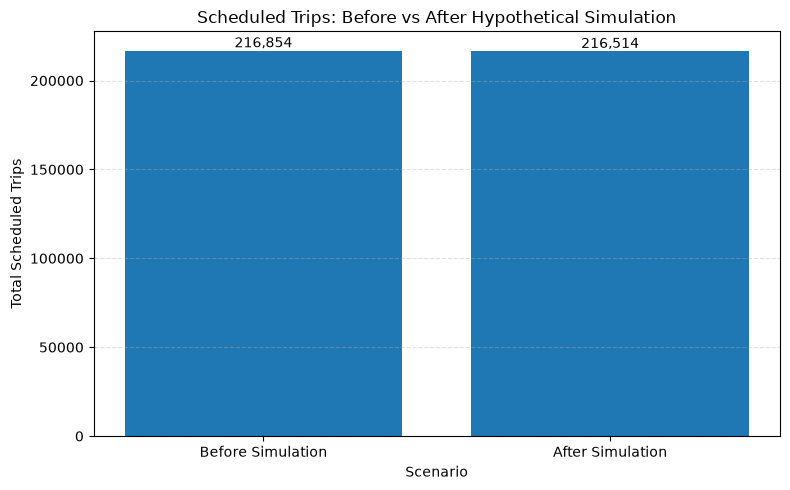

In [45]:

# Visualize scheduled trips before and after simulation

labels = ["Before Simulation", "After Simulation"]
trip_values = [
    original_route_data["scheduled_trip_count"].sum(),
    schedule_scenario["scheduled_trip_count"].sum()
]

plt.figure(figsize=(8, 5))
bars = plt.bar(labels, trip_values)

plt.title("Scheduled Trips: Before vs After Hypothetical Simulation")
plt.xlabel("Scenario")
plt.ylabel("Total Scheduled Trips")
plt.grid(axis="y", linestyle="--", alpha=0.4)

for bar, value in zip(bars, trip_values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:,.0f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()


## 38. Route-Level Schedule Comparison

This visualization compares scheduled trips for each investigated route before and after the hypothetical 10% adjustment.


# Prepare route-level comparison

route_comparison = schedule_scenario.loc[
    review_mask,
    [
        "city",
        "route_id",
        "Original_Trip_Count",
        "scheduled_trip_count"
    ]
].copy()

route_comparison["Route_Label"] = (
    route_comparison["city"].str.title()
    + " - "
    + route_comparison["route_id"].astype(str)
)

# Plot grouped bar chart
x = np.arange(len(route_comparison))
width = 0.38

plt.figure(figsize=(12, 6))

plt.bar(
    x - width / 2,
    route_comparison["Original_Trip_Count"],
    width,
    label="Before Simulation"
)

plt.bar(
    x + width / 2,
    route_comparison["scheduled_trip_count"],
    width,
    label="After Simulation"
)

plt.xticks(
    x,
    route_comparison["Route_Label"],
    rotation=35,
    ha="right"
)

plt.title("Route-Level Scheduled Trips: Before vs After")
plt.xlabel("Investigated Routes")
plt.ylabel("Scheduled Trip Count")
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

display(route_comparison)


## 39. Saving Module 6 Deliverables

This step exports model inference results, clustering analysis, route investigation findings, and hypothetical optimization results into separate CSV files.

The original Module 1–5 files remain unchanged.

In [47]:

# Create Module 6 output folders

module6_data_dir = PROJECT_DIR / "data" / "processed"
module6_report_dir = PROJECT_DIR / "reports"
module6_visual_dir = PROJECT_DIR / "visualizations"

module6_data_dir.mkdir(parents=True, exist_ok=True)
module6_report_dir.mkdir(parents=True, exist_ok=True)
module6_visual_dir.mkdir(parents=True, exist_ok=True)

# Save Module 6 CSV deliverables
module6_outputs = {
    "module6_classification_inference.csv": inference_results,
    "module6_kmeans_inference.csv": kmeans_results,
    "module6_dbscan_analysis.csv": dbscan_results,
    "module6_combined_clustering_analysis.csv": combined_results,
    "module6_route_analysis.csv": original_route_data,
    "module6_final_investigation_findings.csv": final_findings,
    "module6_hypothetical_schedule_scenario.csv": schedule_scenario,
    "module6_simulation_comparison.csv": scenario_comparison,
    "module6_route_level_comparison.csv": route_comparison
}

for filename, dataframe in module6_outputs.items():
    output_path = module6_data_dir / filename
    dataframe.to_csv(output_path, index=False)
    print("Saved:", output_path.name, "| Rows:", len(dataframe))

print("\nModule 6 CSV files saved:", len(module6_outputs))
print("Output directory:", module6_data_dir)


Saved: module6_classification_inference.csv | Rows: 4721
Saved: module6_kmeans_inference.csv | Rows: 7312
Saved: module6_dbscan_analysis.csv | Rows: 7312
Saved: module6_combined_clustering_analysis.csv | Rows: 7312
Saved: module6_route_analysis.csv | Rows: 7312
Saved: module6_final_investigation_findings.csv | Rows: 6
Saved: module6_hypothetical_schedule_scenario.csv | Rows: 7312
Saved: module6_simulation_comparison.csv | Rows: 5
Saved: module6_route_level_comparison.csv | Rows: 6

Module 6 CSV files saved: 9
Output directory: C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\data\processed


## 40. Saving Module 6 Visualizations

This step saves the before-and-after scheduled trip comparison charts as PNG images for documentation and presentation.

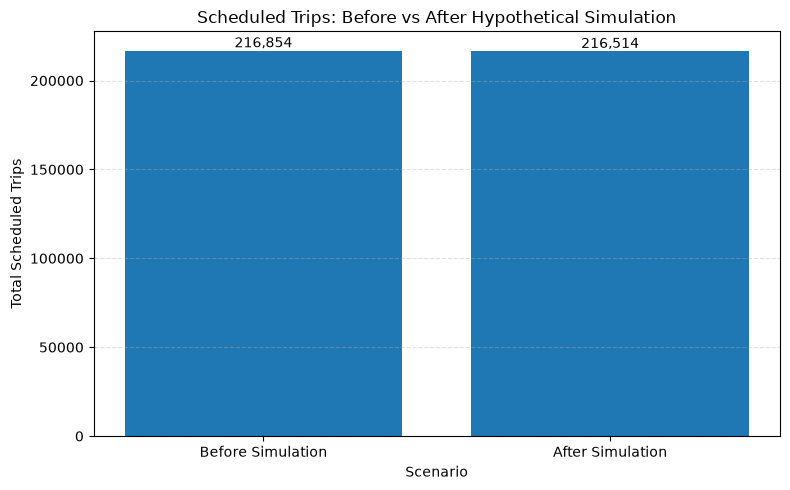

Saved: module6_total_trip_comparison.png


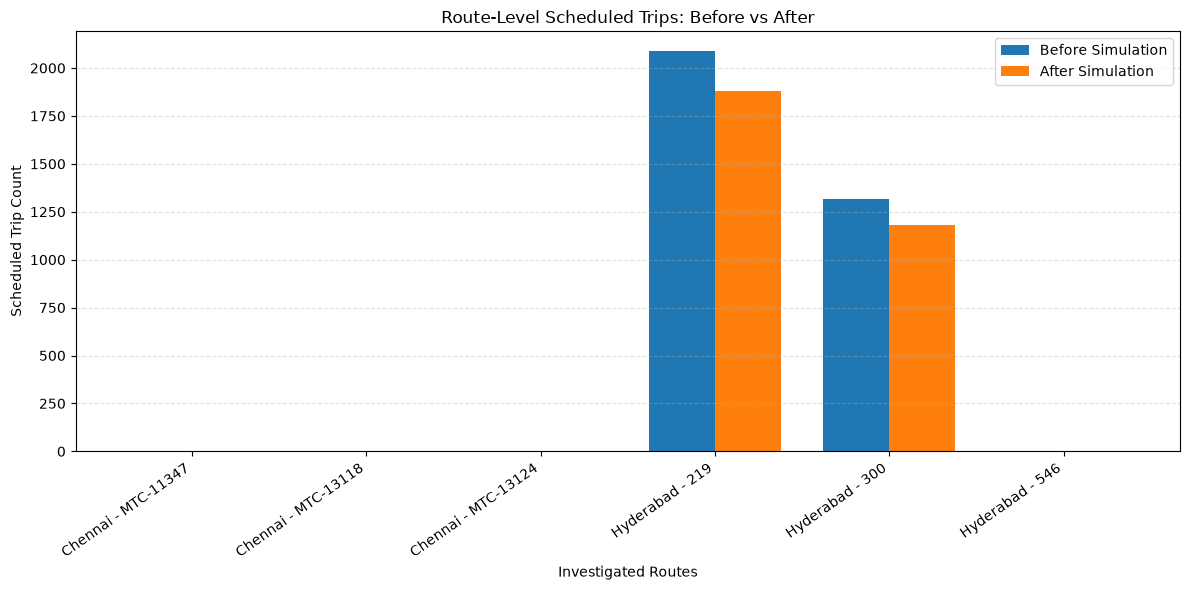

Saved: module6_route_trip_comparison.png


In [48]:

# Save total scheduled trips comparison chart

plt.figure(figsize=(8, 5))

labels = ["Before Simulation", "After Simulation"]
trip_values = [
    original_route_data["scheduled_trip_count"].sum(),
    schedule_scenario["scheduled_trip_count"].sum()
]

bars = plt.bar(labels, trip_values)

plt.title("Scheduled Trips: Before vs After Hypothetical Simulation")
plt.xlabel("Scenario")
plt.ylabel("Total Scheduled Trips")
plt.grid(axis="y", linestyle="--", alpha=0.4)

for bar, value in zip(bars, trip_values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:,.0f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()

total_chart_path = module6_visual_dir / "module6_total_trip_comparison.png"
plt.savefig(total_chart_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", total_chart_path.name)


# Save route-level comparison chart

x = np.arange(len(route_comparison))
width = 0.38

plt.figure(figsize=(12, 6))

plt.bar(
    x - width / 2,
    route_comparison["Original_Trip_Count"],
    width,
    label="Before Simulation"
)

plt.bar(
    x + width / 2,
    route_comparison["scheduled_trip_count"],
    width,
    label="After Simulation"
)

plt.xticks(x, route_comparison["Route_Label"], rotation=35, ha="right")
plt.title("Route-Level Scheduled Trips: Before vs After")
plt.xlabel("Investigated Routes")
plt.ylabel("Scheduled Trip Count")
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()

route_chart_path = module6_visual_dir / "module6_route_trip_comparison.png"
plt.savefig(route_chart_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", route_chart_path.name)


In [51]:
print(report_path.read_text(encoding="utf-8"))

PASTE THE COMPLETE MARKDOWN REPORT FROM THE PREVIOUS CELL HERE


In [53]:

report_content = """# MODULE 6: MODEL INFERENCE AND ROUTE OPTIMIZATION

## 1. Introduction
Module 6 applies trained machine learning models to public transportation data to analyze route patterns, identify unusual routes, and explore operational improvements.

## 2. Objectives
- Load trained models from Module 5.
- Perform K-Means, DBSCAN, Random Forest, and XGBoost inference.
- Identify unusual route patterns.
- Investigate GTFS data-quality issues.
- Simulate hypothetical schedule changes.
- Compare original and simulated results.

## 3. Model Inference

Four trained models were successfully loaded:
- K-Means
- DBSCAN
- Random Forest
- XGBoost

Classification dataset: 4,721 records.

K-Means analyzed 7,312 routes.

| Cluster | Routes |
|---|---:|
| 0 | 6525 |
| 1 | 180 |
| 2 | 227 |
| 3 | 380 |

DBSCAN results:

| Point Type | Count |
|---|---:|
| Core | 7305 |
| Border | 1 |
| Noise | 6 |

## 4. Route Investigation

Six routes were investigated.

Chennai:
- MTC-11347: 4 trips, 11 stops.
- MTC-13118: 2 trips, 13 stops.
- MTC-13124: 2 trips, 10 stops.

No missing stop references or identified time anomalies were found in the checks performed.

Hyderabad:
- Route 219: 2,087 trips; 1,680 exceeded 24 GTFS hours and 247 exceeded 48 hours.
- Route 300: 1,314 trips; two trips had extremely long calculated durations.
- Route 546: Four trips; average coordinate-based straight-line distance approximately 718.30 km. Two trips had stop gaps near 199 km.

These findings require verification with the GTFS data provider.

## 5. Hypothetical Schedule Optimization

A separate simulation dataset was created. A hypothetical 10% reduction was applied to six routes selected for investigation.

Due to whole-trip rounding, only Hyderabad routes 219 and 300 had reduced trip counts.

This is a mathematical simulation, not a validated operational recommendation.

## 6. Before-and-After Comparison

| Metric | Before | After |
|---|---:|---:|
| Route Count | 7312 | 7312 |
| Scheduled Trips | 216854 | 216514 |
| Stop Count (route-level sum) | 259447 | 259447 |
| Estimated Distance (km) | 157563.96 | 157563.96 |
| Operating Days (route-level sum) | 49874 | 49874 |

Scheduled trips decreased by 340, approximately 0.157%.

## 7. Visualizations

- Total scheduled trips before and after simulation.
- Route-level scheduled trips before and after simulation.

## 8. Deliverables

Nine CSV files and two PNG visualizations were saved.

## 9. Limitations

- Actual passenger-demand data was unavailable.
- DBSCAN noise does not automatically mean route inefficiency.
- GTFS times above 24 hours are not automatically invalid.
- Straight-line distance is not actual road distance.
- The schedule adjustment is hypothetical.
- Classification inference results are not independent test results.

## 10. Conclusion

Module 6 successfully applied trained machine learning models, analyzed unusual public transport route patterns, investigated GTFS data-quality issues, and created a hypothetical schedule simulation.

Further validation using passenger demand, verified route geometry, and operational requirements is necessary before implementing real-world changes.
"""

report_path.write_text(report_content, encoding="utf-8")

print("Report saved:", report_path.exists())
print("Report size:", report_path.stat().st_size, "bytes")


Report saved: True
Report size: 3250 bytes


In [54]:

# Verify all Module 6 deliverables

expected_files = [
    module6_data_dir / "module6_classification_inference.csv",
    module6_data_dir / "module6_kmeans_inference.csv",
    module6_data_dir / "module6_dbscan_analysis.csv",
    module6_data_dir / "module6_combined_clustering_analysis.csv",
    module6_data_dir / "module6_route_analysis.csv",
    module6_data_dir / "module6_final_investigation_findings.csv",
    module6_data_dir / "module6_hypothetical_schedule_scenario.csv",
    module6_data_dir / "module6_simulation_comparison.csv",
    module6_data_dir / "module6_route_level_comparison.csv",
    module6_visual_dir / "module6_total_trip_comparison.png",
    module6_visual_dir / "module6_route_trip_comparison.png",
    report_path
]

verification_results = []

for file_path in expected_files:
    verification_results.append({
        "File": file_path.name,
        "Exists": file_path.exists(),
        "Size_KB": round(file_path.stat().st_size / 1024, 2)
        if file_path.exists() else 0
    })

verification_df = pd.DataFrame(verification_results)

display(verification_df)

print("\nTotal files:", len(expected_files))
print("Files verified:", verification_df["Exists"].sum())
print("Missing files:", (~verification_df["Exists"]).sum())


,File,Exists,Size_KB
0,module6_classification_inference.csv,True,142.76
1,module6_kmeans_inference.csv,True,184.10
2,module6_dbscan_analysis.csv,True,219.83
3,module6_combined_clustering_analysis.csv,True,234.13
4,module6_route_analysis.csv,True,775.40
5,module6_final_investigation_findings.csv,True,0.96
6,module6_hypothetical_schedule_scenario.csv,True,864.40
7,module6_simulation_comparison.csv,True,0.27
8,module6_route_level_comparison.csv,True,0.31
9,module6_total_trip_comparison.png,True,79.06



Total files: 12
Files verified: 12
Missing files: 0
